In [5]:
import numpy as np
import pandas as pd
import seaborn as sns
import plotly.express as px
import matplotlib.pyplot as plt

from pathlib import Path
print("Libraries imported successfully.")

Libraries imported successfully.


In [6]:
DATA_PATH = Path("../data/raw/HHS_Unaccompanied_Alien_Children_Program.csv")

df = pd.read_csv(DATA_PATH)


Basic Inspection

In [7]:
df.head()

,Date,Children apprehended and placed in CBP custody*,Children in CBP custody,Children transferred out of CBP custody,Children in HHS Care,Children discharged from HHS Care
0,"December 21, 2025",6.0,18.0,11.0,"2,484",14.0
1,"December 18, 2025",11.0,50.0,6.0,"2,472",16.0
2,"December 17, 2025",7.0,31.0,11.0,"2,481",10.0
3,"December 16, 2025",8.0,54.0,15.0,"2,468",9.0
4,"December 15, 2025",11.0,42.0,9.0,"2,470",7.0


In [8]:
print(f"Rows    : {df.shape[0]}")
print(f"Columns : {df.shape[1]}")

Rows    : 1170
Columns : 6


In [9]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1170 entries, 0 to 1169
Data columns (total 6 columns):
 #   Column                                           Non-Null Count  Dtype  
---  ------                                           --------------  -----  
 0   Date                                             720 non-null    object 
 1   Children apprehended and placed in CBP custody*  720 non-null    float64
 2   Children in CBP custody                          720 non-null    float64
 3   Children transferred out of CBP custody          720 non-null    float64
 4   Children in HHS Care                             720 non-null    object 
 5   Children discharged from HHS Care                720 non-null    float64
dtypes: float64(4), object(2)
memory usage: 55.0+ KB
None


In [10]:
numeric_col = df.select_dtypes(include='number').columns
print(numeric_col)
non_numeric_col = df.select_dtypes(exclude='number').columns
print(non_numeric_col)


Index(['Children apprehended and placed in CBP custody*',
       'Children in CBP custody', 'Children transferred out of CBP custody',
       'Children discharged from HHS Care'],
      dtype='object')
Index(['Date', 'Children in HHS Care'], dtype='object')


# Data Preprocessing

Data cleaning

In [11]:
# create working copy 
data_copy = df.copy()

In [12]:
blank_rows = data_copy.isna().all(axis=1)

print(f"Total rows              : {len(data_copy)}")
print(f"Completely blank rows   : {blank_rows.sum()}")
print(f"Rows with actual data   : {(~blank_rows).sum()}")

Total rows              : 1170
Completely blank rows   : 450
Rows with actual data   : 720


In [13]:
pd.DataFrame({
    'missing row' : data_copy.isnull().sum(),
    'missing %'   : data_copy.isnull().sum()/len(data_copy)
})

,missing row,missing %
Date,450,0.384615
Children apprehended and placed in CBP custody*,450,0.384615
Children in CBP custody,450,0.384615
Children transferred out of CBP custody,450,0.384615
Children in HHS Care,450,0.384615
Children discharged from HHS Care,450,0.384615


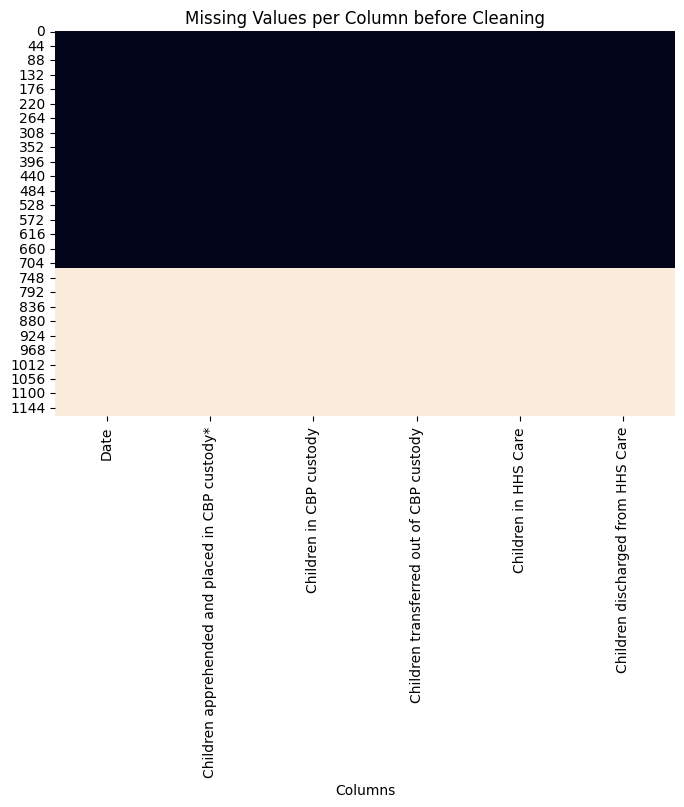

In [14]:
plt.figure(figsize=(8,5))
sns.heatmap(data_copy.isnull(), cbar=False)
plt.title("Missing Values per Column before Cleaning")
plt.xlabel("Columns")
plt.show()


In [15]:
duplicate_rows = data_copy.duplicated().sum()
print(f"Duplicate rows: {duplicate_rows}")

Duplicate rows: 449


In [16]:
# Remove Blank Rows for Analysis
data_copy = data_copy.loc[~blank_rows]
print("After Removing Blank Row:", data_copy.shape)

After Removing Blank Row: (720, 6)


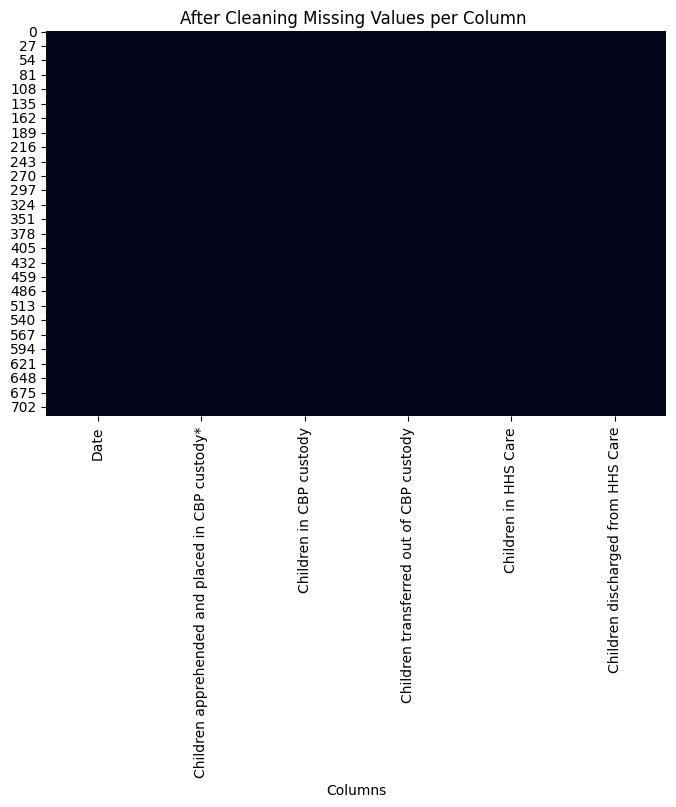

In [17]:
plt.figure(figsize=(8,5))
sns.heatmap(data_copy.isnull(), cbar=False)
plt.title("After Cleaning Missing Values per Column ")
plt.xlabel("Columns")
plt.show()


In [18]:
# for satisfaction of missing values, we can create a summary table that shows the count and percentage of missing values for each column in the dataset.

missing_summary = pd.DataFrame({
    "Missing Count": data_copy.isna().sum(),
    "Missing %": (data_copy.isna().mean() * 100).round(2)
})

display(missing_summary)

,Missing Count,Missing %
Date,0,0.0
Children apprehended and placed in CBP custody*,0,0.0
Children in CBP custody,0,0.0
Children transferred out of CBP custody,0,0.0
Children in HHS Care,0,0.0
Children discharged from HHS Care,0,0.0


EDA

In [19]:
date_column = "Date"

count_columns = [
    "Children apprehended and placed in CBP custody*",
    "Children in CBP custody",
    "Children transferred out of CBP custody",
    "Children in HHS Care",
    "Children discharged from HHS Care"
]

# Start from the source data so cleaning is reproducible
uac = df.copy()

# Remove rows only when every field is blank
uac = uac.dropna(how="all").copy()

# Convert dates
uac[date_column] = pd.to_datetime(
    uac[date_column], errors="coerce"
)

# Convert comma-formatted counts to numeric values
for col in count_columns:
    uac[col] = pd.to_numeric(
        uac[col].astype("string")
              .str.replace(",", "", regex=False)
              .str.strip(),
        errors="coerce"
    )

# Report invalid values introduced by conversion
conversion_issues = pd.DataFrame({
    "Missing After Conversion": uac.isna().sum()
})

display(conversion_issues)

# Sort chronologically
uac = uac.sort_values("Date").reset_index(drop=True)

print("Original source rows:", len(df))
print("Completely blank rows:", df.isna().all(axis=1).sum())
print("Clean analytical shape:", uac.shape)
print("Date range:", uac["Date"].min(), "to", uac["Date"].max())
print("Duplicate dates:", uac["Date"].duplicated().sum())


,Missing After Conversion
Date,0
Children apprehended and placed in CBP custody*,0
Children in CBP custody,0
Children transferred out of CBP custody,0
Children in HHS Care,0
Children discharged from HHS Care,0


Original source rows: 1170
Completely blank rows: 450
Clean analytical shape: (720, 6)
Date range: 2023-01-12 00:00:00 to 2025-12-21 00:00:00
Duplicate dates: 0


In [20]:

#  DATA QUALITY AUDIT
quality_audit = pd.DataFrame({
    "Data Type": uac.dtypes.astype(str),
    "Missing Count": uac.isna().sum(),
    "Missing Percentage": (uac.isna().mean() * 100).round(2),
    "Unique Values": uac.nunique()
})

display(quality_audit)

# Check for negative and fractional counts
negative_counts = (uac[count_columns] < 0).sum()

fractional_counts = (
    uac[count_columns].notna()
    & (uac[count_columns] % 1 != 0)
).sum()

print("\nNegative values by column:")
display(negative_counts.to_frame("Negative Count"))

print("\nFractional values by column:")
display(fractional_counts.to_frame("Fractional Count"))

# Check remaining missing values
if uac.isna().sum().sum() == 0:
    print("PASS: No missing values remain in the analytical dataset.")
else:
    print("REVIEW REQUIRED: Missing values remain.")

if negative_counts.sum() == 0:
    print("PASS: No negative counts detected.")
else:
    print("REVIEW REQUIRED: Negative counts detected.")

if fractional_counts.sum() == 0:
    print("PASS: All recorded counts are whole numbers.")
else:
    print("REVIEW REQUIRED: Some counts are fractional.")


,Data Type,Missing Count,Missing Percentage,Unique Values
Date,datetime64[ns],0,0.0,720
Children apprehended and placed in CBP custody*,Float64,0,0.0,169
Children in CBP custody,Float64,0,0.0,216
Children transferred out of CBP custody,Float64,0,0.0,185
Children in HHS Care,Int64,0,0.0,642
Children discharged from HHS Care,Float64,0,0.0,285



Negative values by column:


,Negative Count
Children apprehended and placed in CBP custody*,0
Children in CBP custody,0
Children transferred out of CBP custody,0
Children in HHS Care,0
Children discharged from HHS Care,0



Fractional values by column:


,Fractional Count
Children apprehended and placed in CBP custody*,0
Children in CBP custody,0
Children transferred out of CBP custody,0
Children in HHS Care,0
Children discharged from HHS Care,0


PASS: No missing values remain in the analytical dataset.
PASS: No negative counts detected.
PASS: All recorded counts are whole numbers.


In [21]:
date_index = (
    uac[["Date"]]
    .drop_duplicates()
    .sort_values("Date")
    .reset_index(drop=True)
)

date_index["Days Since Previous Report"] = (
    date_index["Date"].diff().dt.days
)

min_date = uac["Date"].min()
max_date = uac["Date"].max()

calendar = pd.date_range(min_date, max_date, freq="D")
observed_dates = pd.DatetimeIndex(uac["Date"].dropna().unique())
missing_dates = calendar.difference(observed_dates)

print("Earliest date:", min_date.date())
print("Latest date:", max_date.date())
print("Calendar days in range:", len(calendar))
print("Observed reporting dates:", len(observed_dates))
print("Unobserved calendar dates:", len(missing_dates))
print("Largest reporting gap:",
      date_index["Days Since Previous Report"].max(), "days")

print("\nGap frequency:")
display(
    date_index["Days Since Previous Report"]
    .value_counts()
    .sort_index()
    .rename_axis("Gap in Days")
    .to_frame("Frequency")
)

# Yearly observation counts
yearly_counts = (
    uac.groupby(uac["Date"].dt.year)
    .size()
    .rename("Observation Count")
    .to_frame()
)

display(yearly_counts)

# Important: do not fill unobserved dates with zero
print(
    "Interpretation: This dataset has irregular reporting dates. "
    "Unobserved dates are not assumed to represent zero children."
)


Earliest date: 2023-01-12
Latest date: 2025-12-21
Calendar days in range: 1075
Observed reporting dates: 720
Unobserved calendar dates: 355
Largest reporting gap: 10.0 days

Gap frequency:


,Frequency
Gap in Days,
1.0,558
2.0,10
3.0,122
4.0,23
5.0,3
6.0,1
7.0,1
10.0,1


,Observation Count
Date,
2023,230
2024,251
2025,239


Interpretation: This dataset has irregular reporting dates. Unobserved dates are not assumed to represent zero children.


In [22]:
# MISSING CALENDAR DATE ANALYSIS

complete_calendar = pd.date_range(
    start=min_date,
    end=max_date,
    freq="D"
)

observed_dates = set(uac["Date"])

missing_calendar_dates = [
    date for date in complete_calendar
    if date not in observed_dates
]

print("Expected calendar dates :", len(complete_calendar))
print("Observed dates          :", len(observed_dates))
print("Unobserved dates        :", len(missing_calendar_dates))

Expected calendar dates : 1075
Observed dates          : 720
Unobserved dates        : 355


In [23]:
# MONTH-WISE REPORTING PATTERN

monthly_observations = (
    uac["Date"].dt.month_name().value_counts())
display(monthly_observations)

px.histogram(
    x= monthly_observations.index,
    y= monthly_observations.values,
    color=monthly_observations.index,
    opacity=0.8,
    labels={"x": "Month", "y": "Observation Count"},
    title="Monthly Observation Counts"
)


Date
April        66
October      64
July         63
September    63
March        62
May          61
August       59
February     58
November     58
June         58
December     56
January      52
Name: count, dtype: int64

In [24]:
# DESCRIPTIVE STATISTICS

descriptive_stats = (
    uac.describe().T
)

descriptive_stats["missing"] = uac.isna().sum()

display(descriptive_stats)

,count,mean,min,25%,50%,75%,max,std,missing
Date,720,2024-07-06 05:29:59.999999744,2023-01-12 00:00:00,2023-10-16 18:00:00,2024-07-05 12:00:00,2025-03-25 06:00:00,2025-12-21 00:00:00,NaN,0
Children apprehended and placed in CBP custody*,720.0,93.523611,0.0,12.0,99.0,147.25,333.0,72.646625,0
Children in CBP custody,720.0,171.494444,7.0,36.0,193.0,263.25,531.0,126.354965,0
Children transferred out of CBP custody,720.0,128.668056,0.0,14.0,157.0,199.25,440.0,97.322012,0
Children in HHS Care,720.0,6061.275,1972.0,2467.75,6406.5,8010.25,11516.0,2833.070109,0
Children discharged from HHS Care,720.0,173.406944,0.0,19.75,181.0,267.0,505.0,125.702841,0


In [25]:

#  OPERATIONAL VALIDATION

uac["Flag: Transfers > CBP Snapshot"] = (
    uac["Children transferred out of CBP custody"]
    > uac["Children in CBP custody"]
)

uac["Flag: Discharges > HHS Snapshot"] = (
    uac["Children discharged from HHS Care"]
    > uac["Children in HHS Care"]
)

uac["Flag: Transfers > Same-Day Apprehensions"] = (
    uac["Children transferred out of CBP custody"]
    > uac["Children apprehended and placed in CBP custody*"]
)

validation_summary = pd.DataFrame({
    "Check": [
        "Transfers greater than CBP custody snapshot",
        "Discharges greater than HHS care snapshot",
        "Transfers greater than same-day apprehensions"
    ],
    "Flagged Observations": [
        int(uac["Flag: Transfers > CBP Snapshot"].sum()),
        int(uac["Flag: Discharges > HHS Snapshot"].sum()),
        int(uac["Flag: Transfers > Same-Day Apprehensions"].sum())
    ]
})

display(validation_summary)

# Inspect flagged records without deleting them
display(
    uac.loc[
        uac["Flag: Transfers > CBP Snapshot"],
        [
            "Date",
            "Children in CBP custody",
            "Children transferred out of CBP custody"
        ]
    ].sample(10).sort_values(by='Date')
)


,Check,Flagged Observations
0,Transfers greater than CBP custody snapshot,86
1,Discharges greater than HHS care snapshot,0
2,Transfers greater than same-day apprehensions,552


,Date,Children in CBP custody,Children transferred out of CBP custody
47,2023-04-03,139.0,168.0
86,2023-05-29,60.0,71.0
95,2023-06-11,152.0,168.0
96,2023-06-12,118.0,136.0
200,2023-11-15,157.0,201.0
212,2023-12-04,208.0,256.0
226,2023-12-25,196.0,205.0
344,2024-06-12,266.0,274.0
373,2024-07-25,198.0,208.0
494,2025-01-20,118.0,136.0


In [26]:

#  SYSTEM LOAD

uac["Total System Load"] = (
    uac["Children in CBP custody"]
    + uac["Children in HHS Care"]
)

load_summary = uac["Total System Load"].describe().to_frame(
    "Total System Load"
)

display(load_summary)

top_load_dates = (
    uac[
        [
            "Date",
            "Children in CBP custody",
            "Children in HHS Care",
            "Total System Load"
        ]
    ]
    .sort_values("Total System Load", ascending=False)
    .head(10)
)

display(top_load_dates)

# Basic consistency check
assert (
    uac["Total System Load"]
    == uac["Children in CBP custody"] + uac["Children in HHS Care"]
).all()

print("PASS: Total System Load matches CBP Custody + HHS Care.")


,Total System Load
count,720.0
mean,6232.769444
std,2918.458078
min,2002.0
25%,2500.75
50%,6633.5
75%,8249.5
max,11762.0


,Date,Children in CBP custody,Children in HHS Care,Total System Load
224,2023-12-20,246.0,11516,11762.0
225,2023-12-21,228.0,11375,11603.0
223,2023-12-19,185.0,11291,11476.0
220,2023-12-14,157.0,11242,11399.0
161,2023-09-19,287.0,11095,11382.0
162,2023-09-20,310.0,11064,11374.0
219,2023-12-13,181.0,11192,11373.0
163,2023-09-21,285.0,11067,11352.0
226,2023-12-25,196.0,11144,11340.0
222,2023-12-18,188.0,11149,11337.0


PASS: Total System Load matches CBP Custody + HHS Care.


In [27]:
# ============================================================
# HIGHEST SYSTEM LOAD OBSERVATIONS
# ============================================================

top_system_load = (
    uac[
        [
            "Date",
            "Children in CBP custody",
            "Children in HHS Care",
            "Total System Load"
        ]
    ]
    .sort_values(
        "Total System Load",
        ascending=False
    )
    .head(10)
)

display(top_system_load)

,Date,Children in CBP custody,Children in HHS Care,Total System Load
224,2023-12-20,246.0,11516,11762.0
225,2023-12-21,228.0,11375,11603.0
223,2023-12-19,185.0,11291,11476.0
220,2023-12-14,157.0,11242,11399.0
161,2023-09-19,287.0,11095,11382.0
162,2023-09-20,310.0,11064,11374.0
219,2023-12-13,181.0,11192,11373.0
163,2023-09-21,285.0,11067,11352.0
226,2023-12-25,196.0,11144,11340.0
222,2023-12-18,188.0,11149,11337.0


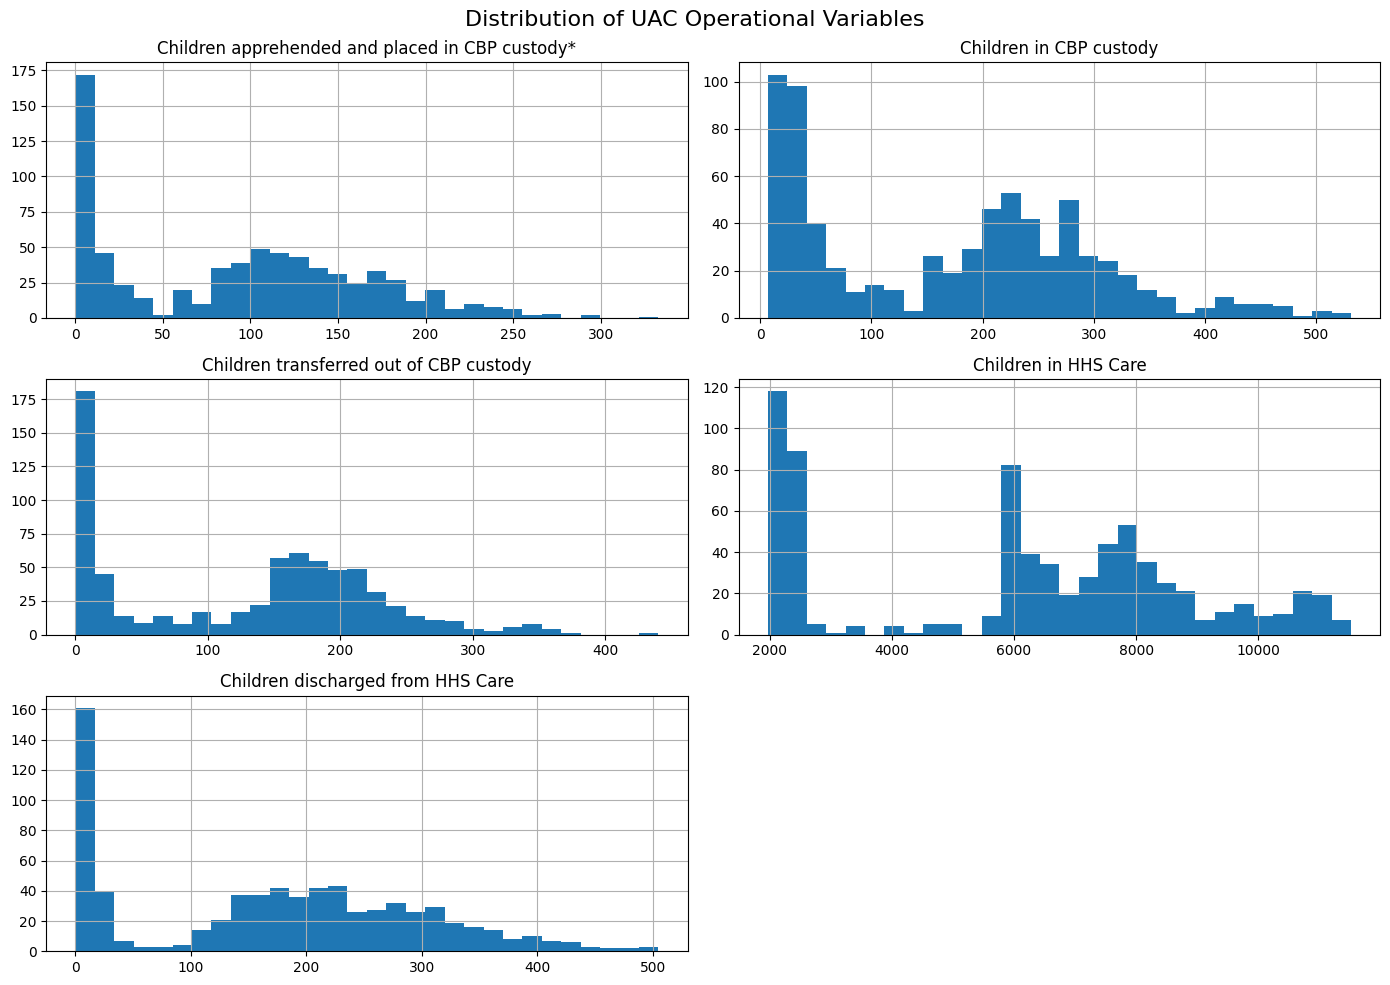

In [28]:

# FINAL INITIAL EDA

uac = uac.sort_values("Date").reset_index(drop=True)

# Distributions of operational variables
uac[count_columns].hist(figsize=(14, 10), bins=30)
plt.suptitle("Distribution of UAC Operational Variables", fontsize=16)
plt.tight_layout()
plt.show()
 

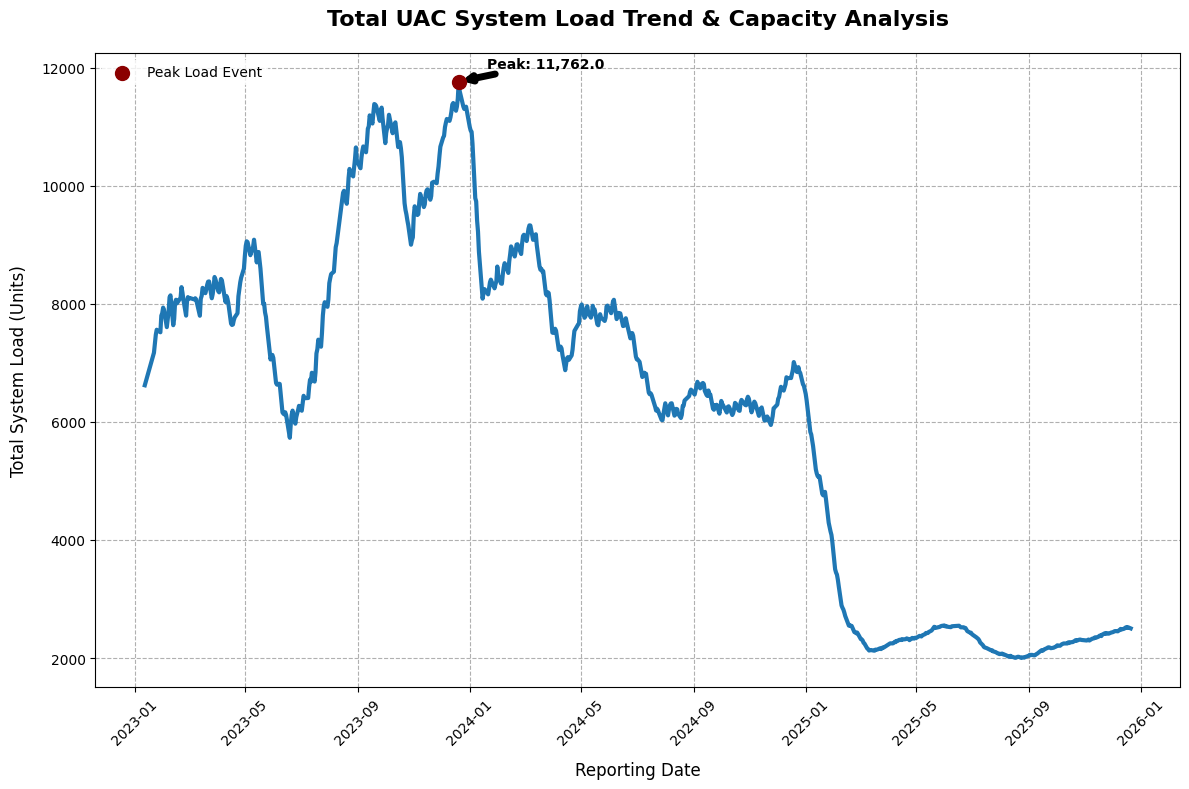

In [29]:
 
# INITIAL SYSTEM LOAD TREND
  

plt.figure(figsize=(12, 8))
plt.grid(True, which='both', linestyle='--')

plt.plot(
    uac["Date"],
    uac["Total System Load"],
    linewidth=3,
  
)

plt.title(
    "Total UAC System Load Trend & Capacity Analysis",
    fontsize=16,
    fontweight="bold",
    pad=20,
)


max_load = uac["Total System Load"].max()
max_date = uac["Date"][uac["Total System Load"].idxmax()]
plt.scatter(
    max_date, max_load, color="darkred", s=100, zorder=5, label="Peak Load Event"
)
plt.annotate(
    f"Peak: {max_load:,}",
    xy=(max_date, max_load),
    xytext=(20, 10),
    textcoords="offset points",
    arrowprops=dict(arrowstyle="->", color="black", lw=5),
    fontweight="bold",
)

plt.xlabel("Reporting Date", fontsize=12, labelpad=10)
plt.ylabel("Total System Load (Units)", fontsize=12, labelpad=10)
plt.legend(loc="upper left", frameon=True, facecolor="white", edgecolor="none")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

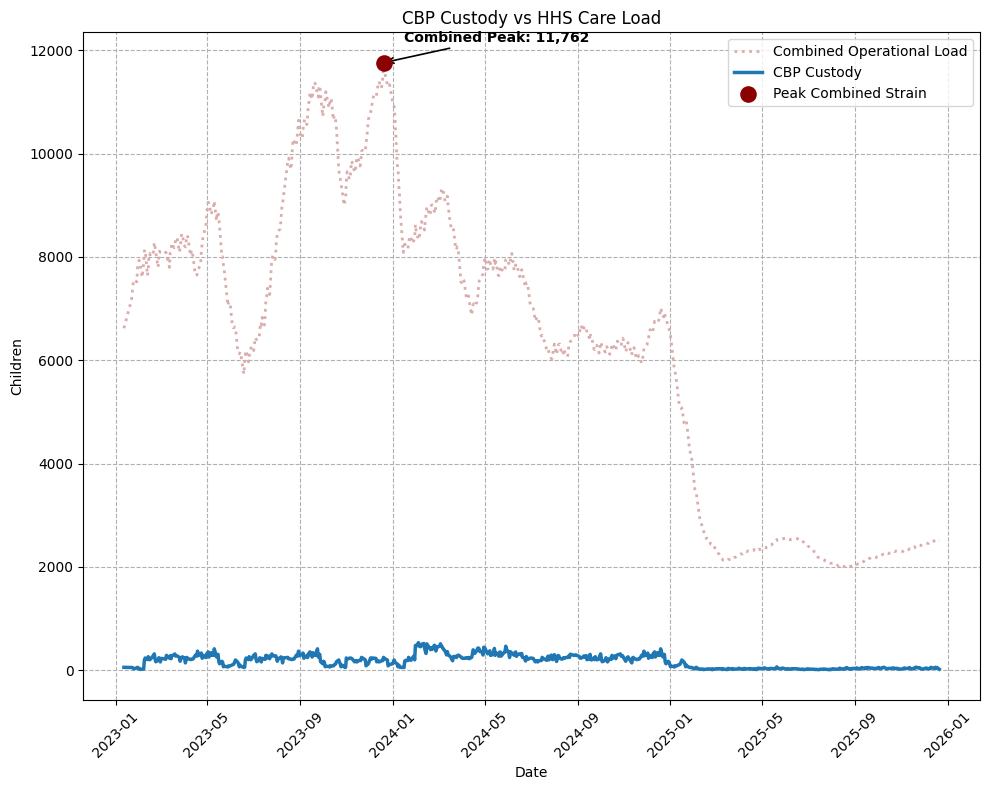

In [30]:
# CBP VS HHS LOAD

plt.figure(figsize=(10, 8))
plt.grid(True, linestyle='--',which = 'major')

total_load = uac["Children in CBP custody"] + uac["Children in HHS Care"]
plt.plot(
    uac["Date"],
    total_load,
    color="#daacac",
    linewidth=2,
    linestyle=":",
    alpha=1,
    label="Combined Operational Load",
)

# 3. Plot agency-specific timelines with enhanced visual weight
plt.plot(
    uac["Date"],
    uac["Children in CBP custody"],
    color="#1f77b4",  # Strong professional blue
    linewidth=2.5,
    label="CBP Custody",
)

max_total = total_load.max()
max_date = uac["Date"][total_load.idxmax()]

plt.scatter(
    max_date,
    max_total,
    color="darkred",
    s=120,
    zorder=5,
    label="Peak Combined Strain",
)
plt.annotate(
    f"Combined Peak: {int(max_total):,}",
    xy=(max_date, max_total),
    xytext=(15, 15),
    textcoords="offset points",
    arrowprops=dict(arrowstyle="->", color="black", lw=1.2),
    fontweight="bold",
)

plt.title("CBP Custody vs HHS Care Load")
plt.xlabel("Date")
plt.ylabel("Children")

plt.legend()
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [31]:
 
# This path assumes the notebook is inside the notebooks/ folder
project_root = Path("..")

processed_dir = project_root / "data" / "processed"
outputs_dir = project_root / "outputs"

processed_dir.mkdir(parents=True, exist_ok=True)
outputs_dir.mkdir(parents=True, exist_ok=True)

# Save chronological cleaned dataset, including validation flags
uac.to_csv(processed_dir / "uac_cleaned.csv", index=False)

# Save quality and validation reports
quality_audit.to_csv(outputs_dir / "data_quality_report.csv")
validation_summary.to_csv(
    outputs_dir / "operational_validation_report.csv",
    index=False
)

# Save top observed load dates
top_load_dates.to_csv(
    outputs_dir / "top_system_load_dates.csv",
    index=False
)

print("Phase 1 outputs saved:")
print(" -", processed_dir / "uac_cleaned.csv")
print(" -", outputs_dir / "data_quality_report.csv")
print(" -", outputs_dir / "operational_validation_report.csv")
print(" -", outputs_dir / "top_system_load_dates.csv")


Phase 1 outputs saved:
 - ..\data\processed\uac_cleaned.csv
 - ..\outputs\data_quality_report.csv
 - ..\outputs\operational_validation_report.csv
 - ..\outputs\top_system_load_dates.csv


## Phase 1: Data Understanding, Cleaning and Initial EDA

### 1. Dataset overview
The source dataset contains 1,170 physical rows and six columns. After removing 450 completely blank rows, 720 valid reporting observations remain.

### 2. Data quality
The retained observations were checked for missing values, invalid dates, duplicate reporting dates, negative counts and fractional count values. Conversion issues and any remaining missing values must be reviewed before the analytical dataset is finalized.

### 3. Reporting frequency
The reporting period extends from January 12, 2023, through December 21, 2025. There are 720 observed reporting dates within a 1,075-day calendar span, with a maximum observed gap of 10 days. The dataset is therefore not a complete daily time series. Unobserved dates are not treated as zero.

### 4. Operational validation
Some records have transfer counts greater than the CBP custody snapshot or same-day apprehensions. These relationships compare flow variables with snapshot counts and do not automatically indicate errors. Such records are retained and flagged for interpretation.

### 5. System-load analysis
Total System Load is defined as CBP Custody plus HHS Care. Initial analysis reports an average observed combined load of approximately 6,232.77 and a maximum of 11,762 on December 20, 2023. These measures represent observed load, not capacity utilization.

### 6. Initial exploratory analysis
Histograms and chronological trend plots were produced to examine distributions and variation across the reporting period. These plots support further investigation of load changes and potential periods of operational pressure.

### 7. Limitations
The dataset does not provide explicit facility capacity, bed availability or staffing limits. It therefore cannot directly establish capacity utilization. Reporting gaps and the distinction between flows and snapshots must be considered in subsequent trend and KPI calculations.

### Phase 1 conclusion
The dataset has undergone initial cleaning, structural validation and exploratory analysis. Phase 1 can be considered complete after the final validation cells run successfully, the date range and record counts match expectations, and the cleaned dataset and audit outputs are saved.

Feature Engineering and KPI Development

In [32]:
# Adjust this path if your notebook is not inside notebooks/
cleaned_path = Path("../data/processed/uac_cleaned.csv")

if not cleaned_path.exists():
    raise FileNotFoundError(
        f"Cleaned dataset not found: {cleaned_path.resolve()}\n"
        "Check your project folder and notebook location."
    )

uac = pd.read_csv(cleaned_path, parse_dates=["Date"])
uac = uac.sort_values("Date").reset_index(drop=True)

count_columns = [
    "Children apprehended and placed in CBP custody*",
    "Children in CBP custody",
    "Children transferred out of CBP custody",
    "Children in HHS Care",
    "Children discharged from HHS Care"
]

required_columns = ["Date"] + count_columns
missing_columns = [
    col for col in required_columns if col not in uac.columns
]

if missing_columns:
    raise ValueError(f"Required columns missing: {missing_columns}")

if uac["Date"].isna().any():
    raise ValueError("Invalid dates found in the cleaned dataset.")

if uac["Date"].duplicated().any():
    raise ValueError("Duplicate dates found. Resolve them before continuing.")

for col in count_columns:
    uac[col] = pd.to_numeric(uac[col], errors="raise")

if uac[count_columns].isna().any().any():
    raise ValueError("Missing numerical values found.")

if (uac[count_columns] < 0).any().any():
    raise ValueError("Negative counts found.")

print("-" * 45)
print("Rows:", len(uac))
print("Columns:", len(uac.columns))
print("Start date:", uac["Date"].min().date())
print("End date:", uac["Date"].max().date())
print("Duplicate dates:", uac["Date"].duplicated().sum())
print("All required checks passed.")
display(uac.head())


---------------------------------------------
Rows: 720
Columns: 10
Start date: 2023-01-12
End date: 2025-12-21
Duplicate dates: 0
All required checks passed.


,Date,Children apprehended and placed in CBP custody*,Children in CBP custody,Children transferred out of CBP custody,Children in HHS Care,Children discharged from HHS Care,Flag: Transfers > CBP Snapshot,Flag: Discharges > HHS Snapshot,Flag: Transfers > Same-Day Apprehensions,Total System Load
0,2023-01-12,33.0,53.0,34.0,6566,436.0,False,False,True,6619.0
1,2023-01-22,32.0,49.0,39.0,7122,227.0,False,False,True,7171.0
2,2023-01-23,32.0,50.0,39.0,7280,181.0,False,False,True,7330.0
3,2023-01-24,47.0,42.0,47.0,7433,175.0,True,False,False,7475.0
4,2023-01-25,20.0,22.0,41.0,7538,180.0,True,False,True,7560.0


In [33]:
cbp_custody = "Children in CBP custody"
transfers = "Children transferred out of CBP custody"
hhs_care = "Children in HHS Care"
discharges = "Children discharged from HHS Care"

# 1. Combined observed system load
uac["Total System Load"] = (
    uac[cbp_custody] + uac[hhs_care]
)

# 2. Net intake pressure proxy
# Positive: transfers exceed discharges
# Negative: discharges exceed transfers
uac["Net Intake Pressure"] = (
    uac[transfers] - uac[discharges]
)

# 3. Net pressure as a percentage of transfers
# Undefined when transfers are zero
uac["Net Pressure Ratio (%)"] = np.where(
    uac[transfers] != 0,
    100 * uac["Net Intake Pressure"] / uac[transfers],
    np.nan
)

# 4. Time elapsed since the previous observation
uac["Days Since Previous Report"] = (
    uac["Date"].diff().dt.total_seconds() / 86400
)

# 5. Change in total system load between recorded observations
uac["Load Change"] = uac["Total System Load"].diff()

# 6. Percentage change from the previous observed load
previous_load = uac["Total System Load"].shift(1)

uac["Load Change (%)"] = np.where(
    previous_load > 0,
    100 * uac["Load Change"] / previous_load,
    np.nan
)

# 7. Change per elapsed calendar day.
# This is a normalized change, not an observed daily count.
uac["Load Change Per Elapsed Day"] = np.where(
    uac["Days Since Previous Report"] > 0,
    uac["Load Change"] / uac["Days Since Previous Report"],
    np.nan
)

feature_columns = [
    "Date",
    "Total System Load",
    "Net Intake Pressure",
    "Net Pressure Ratio (%)",
    "Days Since Previous Report",
    "Load Change",
    "Load Change (%)",
    "Load Change Per Elapsed Day"
]

display(uac[feature_columns].head(10))


,Date,Total System Load,Net Intake Pressure,Net Pressure Ratio (%),Days Since Previous Report,Load Change,Load Change (%),Load Change Per Elapsed Day
0,2023-01-12,6619.0,-402.0,-1182.352941,NaN,NaN,NaN,NaN
1,2023-01-22,7171.0,-188.0,-482.051282,10.0,552.0,8.339628,55.20
2,2023-01-23,7330.0,-142.0,-364.102564,1.0,159.0,2.217264,159.00
3,2023-01-24,7475.0,-128.0,-272.340426,1.0,145.0,1.978172,145.00
4,2023-01-25,7560.0,-139.0,-339.024390,1.0,85.0,1.137124,85.00
5,2023-01-29,7517.0,-292.0,-2654.545455,4.0,-43.0,-0.568783,-10.75
6,2023-01-30,7797.0,-167.0,-575.862069,1.0,280.0,3.724890,280.00
7,2023-01-31,7839.0,-122.0,-338.888889,1.0,42.0,0.538669,42.00
8,2023-02-01,7935.0,-204.0,-755.555556,1.0,96.0,1.224646,96.00
9,2023-02-02,7892.0,-275.0,-1195.652174,1.0,-43.0,-0.541903,-43.00


In [34]:

# ============================================================
#  FEATURE VALIDATION
# ============================================================

assert (
    uac["Total System Load"]
    == uac[cbp_custody] + uac[hhs_care]
).all()

assert (
    uac["Net Intake Pressure"]
    == uac[transfers] - uac[discharges]
).all()

assert uac["Days Since Previous Report"].iloc[1:].gt(0).all()

print("PASS: Total System Load formula verified.")
print("PASS: Net Intake Pressure formula verified.")
print("PASS: Observation gaps are positive.")
print("First observation has no previous load for comparison.")

print("\nCore feature summary:")
display(
    uac[
        [
            "Total System Load",
            "Net Intake Pressure",
            "Load Change",
            "Load Change (%)",
            "Load Change Per Elapsed Day"
        ]
    ].describe().T
)


PASS: Total System Load formula verified.
PASS: Net Intake Pressure formula verified.
PASS: Observation gaps are positive.
First observation has no previous load for comparison.

Core feature summary:


,count,mean,std,min,25%,50%,75%,max
Total System Load,720.0,6232.769444,2918.458078,2002.000000,2500.750000,6633.500000,8249.500000,11762.000000
Net Intake Pressure,720.0,-44.738889,95.863856,-465.000000,-94.250000,-11.500000,5.250000,206.000000
Load Change,719.0,-5.726008,140.279015,-922.000000,-34.000000,6.000000,64.000000,730.000000
Load Change (%),719.0,-0.116894,1.895490,-11.601513,-0.689345,0.123877,0.858314,8.339628
Load Change Per Elapsed Day,719.0,14.206712,86.972775,-339.000000,-27.000000,4.000000,55.600000,360.000000


In [35]:

# ============================================================
# CALENDAR-BASED ROLLING INDICATORS
# ============================================================

# Use Date as the time index for calendar-based rolling windows
time_data = (
    uac.sort_values("Date")
       .set_index("Date")
       .copy()
)

# Metrics to analyze over time
rolling_metrics = [
    "Total System Load",
    "Net Intake Pressure",
    "Children transferred out of CBP custody",
    "Children discharged from HHS Care"
]

for metric in rolling_metrics:
    for days in [7, 14]:
        window_name = f"{days}D"

        # Average of available recorded observations in the window.
        # Missing calendar dates are NOT filled with zero.
        time_data[f"{metric} - {days}D Mean"] = (
            time_data[metric]
            .rolling(window_name, closed="right", min_periods=1)
            .mean()
        )

        # Number of actual observations available in that window
        time_data[f"{metric} - {days}D Observations"] = (
            time_data[metric]
            .rolling(window_name, closed="right", min_periods=1)
            .count()
        )

# Restore Date as a normal column
uac = time_data.reset_index()

rolling_columns = [
    "Date",
    "Total System Load",
    "Total System Load - 7D Mean",
    "Total System Load - 14D Mean",
    "Total System Load - 7D Observations",
    "Total System Load - 14D Observations",
    "Net Intake Pressure",
    "Net Intake Pressure - 7D Mean",
    "Net Intake Pressure - 14D Mean"
]

display(uac[rolling_columns].head(20))

print("PASS: Calendar-based rolling indicators created.")
print("Note: Means use observed records within each window.")


,Date,Total System Load,Total System Load - 7D Mean,Total System Load - 14D Mean,Total System Load - 7D Observations,Total System Load - 14D Observations,Net Intake Pressure,Net Intake Pressure - 7D Mean,Net Intake Pressure - 14D Mean
0,2023-01-12,6619.0,6619.000000,6619.000000,1.0,1.0,-402.0,-402.000000,-402.000000
1,2023-01-22,7171.0,7171.000000,6895.000000,1.0,2.0,-188.0,-188.000000,-295.000000
2,2023-01-23,7330.0,7250.500000,7040.000000,2.0,3.0,-142.0,-165.000000,-244.000000
3,2023-01-24,7475.0,7325.333333,7148.750000,3.0,4.0,-128.0,-152.666667,-215.000000
4,2023-01-25,7560.0,7384.000000,7231.000000,4.0,5.0,-139.0,-149.250000,-199.800000
5,2023-01-29,7517.0,7470.500000,7410.600000,4.0,5.0,-292.0,-175.250000,-177.800000
6,2023-01-30,7797.0,7587.250000,7475.000000,4.0,6.0,-167.0,-181.500000,-176.000000
7,2023-01-31,7839.0,7678.250000,7527.000000,4.0,7.0,-122.0,-180.000000,-168.285714
8,2023-02-01,7935.0,7772.000000,7578.000000,4.0,8.0,-204.0,-196.250000,-172.750000
9,2023-02-02,7892.0,7796.000000,7612.888889,5.0,9.0,-275.0,-212.000000,-184.111111


PASS: Calendar-based rolling indicators created.
Note: Means use observed records within each window.


In [36]:

# ============================================================
# BACKLOG-PRESSURE SIGNAL
# ============================================================

time_data = (
    uac.sort_values("Date")
       .set_index("Date")
       .copy()
)

# One means positive net intake pressure; zero means otherwise
time_data["Positive Net Pressure"] = (
    time_data["Net Intake Pressure"] > 0
).astype(int)

# Count positive-pressure observations in the trailing 7 days
time_data["Positive Pressure Count - 7D"] = (
    time_data["Positive Net Pressure"]
    .rolling("7D", closed="right", min_periods=1)
    .sum()
)

# Count all observations in the same 7-day window
time_data["Observation Count - 7D"] = (
    time_data["Net Intake Pressure"]
    .rolling("7D", closed="right", min_periods=1)
    .count()
)

# Flag only when at least 3 observed records exist
# and all 3 or more have positive net pressure
time_data["Potential Sustained Pressure"] = (
    (time_data["Observation Count - 7D"] >= 3)
    & (time_data["Positive Pressure Count - 7D"] >= 3)
)

uac = time_data.reset_index()

display(
    uac[
        [
            "Date",
            "Net Intake Pressure",
            "Positive Pressure Count - 7D",
            "Observation Count - 7D",
            "Potential Sustained Pressure"
        ]
    ].tail(20)
)

print(
    "Flagged observations:",
    int(uac["Potential Sustained Pressure"].sum())
)


,Date,Net Intake Pressure,Positive Pressure Count - 7D,Observation Count - 7D,Potential Sustained Pressure
700,2025-11-23,21.0,1.0,5.0,False
701,2025-11-24,-4.0,1.0,5.0,False
702,2025-11-25,3.0,2.0,5.0,False
703,2025-11-27,1.0,3.0,4.0,True
704,2025-11-30,10.0,3.0,4.0,True
705,2025-12-01,-5.0,3.0,4.0,True
706,2025-12-02,-2.0,2.0,4.0,False
707,2025-12-03,1.0,3.0,5.0,True
708,2025-12-04,-6.0,2.0,5.0,False
709,2025-12-07,1.0,2.0,5.0,False


Flagged observations: 236


In [37]:

# ============================================================
#  DISCHARGE OFFSET RATIO
# ============================================================

transfers = "Children transferred out of CBP custody"
discharges = "Children discharged from HHS Care"

# Undefined when there are no transfers
uac["Discharge Offset Ratio (%)"] = np.where(
    uac[transfers] > 0,
    100 * uac[discharges] / uac[transfers],
    np.nan
)

# Net pressure as a percentage of transfers, retained for reference
uac["Net Pressure Ratio (%)"] = np.where(
    uac[transfers] > 0,
    100 * uac["Net Intake Pressure"] / uac[transfers],
    np.nan
)

display(
    uac[
        [
            "Date",
            transfers,
            discharges,
            "Net Intake Pressure",
            "Discharge Offset Ratio (%)"
        ]
    ].head(15)
)

print("\nDischarge Offset Ratio summary:")
display(uac["Discharge Offset Ratio (%)"].describe())


,Date,Children transferred out of CBP custody,Children discharged from HHS Care,Net Intake Pressure,Discharge Offset Ratio (%)
0,2023-01-12,34.0,436.0,-402.0,1282.352941
1,2023-01-22,39.0,227.0,-188.0,582.051282
2,2023-01-23,39.0,181.0,-142.0,464.102564
3,2023-01-24,47.0,175.0,-128.0,372.340426
4,2023-01-25,41.0,180.0,-139.0,439.024390
5,2023-01-29,11.0,303.0,-292.0,2754.545455
6,2023-01-30,29.0,196.0,-167.0,675.862069
7,2023-01-31,36.0,158.0,-122.0,438.888889
8,2023-02-01,27.0,231.0,-204.0,855.555556
9,2023-02-02,23.0,298.0,-275.0,1295.652174



Discharge Offset Ratio summary:


count     717.000000
mean      201.351238
std       306.255268
min         0.000000
25%        86.285714
50%       127.804878
75%       203.252033
max      4327.272727
Name: Discharge Offset Ratio (%), dtype: float64

In [38]:

# ============================================================
# RECENT REPEATED PRESSURE
# ============================================================

time_data = (
    uac.sort_values("Date")
       .set_index("Date")
       .copy()
)

time_data["Positive Net Pressure"] = (
    time_data["Net Intake Pressure"] > 0
).astype(int)

time_data["Positive Pressure Count - 7D"] = (
    time_data["Positive Net Pressure"]
    .rolling("7D", closed="right", min_periods=1)
    .sum()
)

time_data["Observation Count - 7D"] = (
    time_data["Net Intake Pressure"]
    .rolling("7D", closed="right", min_periods=1)
    .count()
)

time_data["Recent Repeated Pressure"] = (
    (time_data["Observation Count - 7D"] >= 3)
    & (time_data["Positive Pressure Count - 7D"] >= 3)
    & (time_data["Net Intake Pressure"] > 0)
)

uac = time_data.reset_index()

print(
    "Observations flagged:",
    int(uac["Recent Repeated Pressure"].sum())
)

display(
    uac[
        [
            "Date",
            "Net Intake Pressure",
            "Positive Pressure Count - 7D",
            "Observation Count - 7D",
            "Recent Repeated Pressure"
        ]
    ].tail(20)
)

# Validation
assert (
    uac.loc[
        uac["Recent Repeated Pressure"],
        "Net Intake Pressure"
    ] > 0
).all()

print("PASS: Every flagged observation has positive current pressure.")


Observations flagged: 178


,Date,Net Intake Pressure,Positive Pressure Count - 7D,Observation Count - 7D,Recent Repeated Pressure
700,2025-11-23,21.0,1.0,5.0,False
701,2025-11-24,-4.0,1.0,5.0,False
702,2025-11-25,3.0,2.0,5.0,False
703,2025-11-27,1.0,3.0,4.0,True
704,2025-11-30,10.0,3.0,4.0,True
705,2025-12-01,-5.0,3.0,4.0,False
706,2025-12-02,-2.0,2.0,4.0,False
707,2025-12-03,1.0,3.0,5.0,True
708,2025-12-04,-6.0,2.0,5.0,False
709,2025-12-07,1.0,2.0,5.0,False


PASS: Every flagged observation has positive current pressure.


In [39]:

# ============================================================
#  RATIO QUALITY CHECK
# ============================================================

transfers = "Children transferred out of CBP custody"
discharges = "Children discharged from HHS Care"

uac["Discharge Offset Ratio (%)"] = np.where(
    uac[transfers] > 0,
    100 * uac[discharges] / uac[transfers],
    np.nan
)

valid_ratio = uac["Discharge Offset Ratio (%)"].dropna()

ratio_summary = pd.DataFrame({
    "Metric": [
        "Total observations",
        "Observations with positive transfers",
        "Undefined ratio observations",
        "Median ratio (%)",
        "Mean ratio (%)",
        "90th percentile (%)",
        "Maximum ratio (%)"
    ],
    "Value": [
        len(uac),
        int((uac[transfers] > 0).sum()),
        int((uac[transfers] == 0).sum()),
        valid_ratio.median(),
        valid_ratio.mean(),
        valid_ratio.quantile(0.90),
        valid_ratio.max()
    ]
})

display(ratio_summary)
print(
    "Interpretation: ratio compares recorded discharges "
    "with recorded transfers; it is not a verified service-efficiency rate."
)


,Metric,Value
0,Total observations,720.000000
1,Observations with positive transfers,717.000000
2,Undefined ratio observations,3.000000
3,Median ratio (%),127.804878
4,Mean ratio (%),201.351238
5,90th percentile (%),360.665021
6,Maximum ratio (%),4327.272727


Interpretation: ratio compares recorded discharges with recorded transfers; it is not a verified service-efficiency rate.


In [40]:

# ============================================================
#   FINAL FEATURE CONSOLIDATION & KPI EXPORT
# ============================================================

 

# ------------------------------------------------------------
# 1. Prepare data
# ------------------------------------------------------------
uac = uac.sort_values("Date").copy()
uac["Date"] = pd.to_datetime(uac["Date"])

transfers = "Children transferred out of CBP custody"
discharges = "Children discharged from HHS Care"
cbp_custody = "Children in CBP custody"
hhs_care = "Children in HHS Care"

assert len(uac) == 720, "Unexpected row count."
assert uac["Date"].is_unique, "Duplicate reporting dates detected."

# Remove obsolete pressure flag, if present
uac = uac.drop(
    columns=["Potential Sustained Pressure"],
    errors="ignore"
)

# ------------------------------------------------------------
# 2. Recalculate core indicators
# ------------------------------------------------------------
uac["Total System Load"] = uac[cbp_custody] + uac[hhs_care]

uac["Net Intake Pressure"] = (
    uac[transfers] - uac[discharges]
)

uac["Discharge Offset Ratio (%)"] = np.where(
    uac[transfers] > 0,
    100 * uac[discharges] / uac[transfers],
    np.nan
)

uac["Days Since Previous Report"] = (
    uac["Date"].diff().dt.days
)

uac["Load Change"] = uac["Total System Load"].diff()

uac["Load Change (%)"] = (
    uac["Total System Load"].pct_change() * 100
)

uac["Load Change Per Elapsed Day"] = (
    uac["Load Change"] / uac["Days Since Previous Report"]
)

# ------------------------------------------------------------
# 3. Calendar-based rolling features
# ------------------------------------------------------------
time_data = (
    uac.set_index("Date")
       .sort_index()
       .copy()
)

rolling_metrics = {
    "Total System Load": "Total System Load",
    "Net Intake Pressure": "Net Intake Pressure",
    transfers: "Transfers",
    discharges: "Discharges"
}

for source_col, label in rolling_metrics.items():
    for days in [7, 14]:
        rolling = time_data[source_col].rolling(
            f"{days}D",
            closed="right",
            min_periods=1
        )

        time_data[f"{label} Rolling Mean - {days}D"] = (
            rolling.mean()
        )

        time_data[f"Observation Count - {days}D"] = (
            rolling.count()
        )

# ------------------------------------------------------------
# 4. Corrected repeated-pressure indicator
# ------------------------------------------------------------
time_data["Positive Net Pressure"] = (
    time_data["Net Intake Pressure"] > 0
).astype(int)

time_data["Positive Pressure Count - 7D"] = (
    time_data["Positive Net Pressure"]
    .rolling("7D", closed="right", min_periods=1)
    .sum()
)

time_data["Recent Repeated Pressure"] = (
    (time_data["Observation Count - 7D"] >= 3)
    & (time_data["Positive Pressure Count - 7D"] >= 3)
    & (time_data["Net Intake Pressure"] > 0)
)

uac = time_data.reset_index()

# ------------------------------------------------------------
# 5. Build KPI summary
# ------------------------------------------------------------
valid_ratios = uac["Discharge Offset Ratio (%)"].dropna()
valid_load_changes = uac["Load Change"].dropna()
valid_load_pct = uac["Load Change (%)"].dropna()
valid_daily_change = uac["Load Change Per Elapsed Day"].dropna()

latest = uac.iloc[-1]
peak_idx = uac["Total System Load"].idxmax()
peak = uac.loc[peak_idx]

kpi_summary = pd.DataFrame([
    {
        "KPI": "Latest Observed System Load",
        "Value": latest["Total System Load"],
        "Unit": "children",
        "Interpretation": "CBP custody plus HHS care on the latest reporting date"
    },
    {
        "KPI": "Latest Reporting Date",
        "Value": latest["Date"].strftime("%Y-%m-%d"),
        "Unit": "date",
        "Interpretation": "Most recent date available in the dataset"
    },
    {
        "KPI": "Peak Observed System Load",
        "Value": peak["Total System Load"],
        "Unit": "children",
        "Interpretation": "Maximum combined observed load"
    },
    {
        "KPI": "Date of Peak System Load",
        "Value": peak["Date"].strftime("%Y-%m-%d"),
        "Unit": "date",
        "Interpretation": "Date on which maximum combined load was observed"
    },
    {
        "KPI": "Mean Net Intake Pressure",
        "Value": uac["Net Intake Pressure"].mean(),
        "Unit": "children per observation",
        "Interpretation": "Mean transfers minus discharges; a flow proxy, not verified net HHS intake"
    },
    {
        "KPI": "Positive Pressure Frequency",
        "Value": 100 * (uac["Net Intake Pressure"] > 0).mean(),
        "Unit": "%",
        "Interpretation": "Share of observations with transfers greater than discharges"
    },
    {
        "KPI": "Recent Repeated Pressure Frequency",
        "Value": 100 * uac["Recent Repeated Pressure"].mean(),
        "Unit": "%",
        "Interpretation": "Share of observations meeting the defined repeated-pressure rule"
    },
    {
        "KPI": "Median Discharge Offset Ratio",
        "Value": valid_ratios.median(),
        "Unit": "%",
        "Interpretation": "Median recorded discharges divided by recorded transfers"
    },
    {
        "KPI": "90th Percentile Discharge Offset Ratio",
        "Value": valid_ratios.quantile(0.90),
        "Unit": "%",
        "Interpretation": "Upper-tail ratio; can be sensitive to small transfer counts"
    },
    {
        "KPI": "Load Change Standard Deviation",
        "Value": valid_load_changes.std(),
        "Unit": "children per observed transition",
        "Interpretation": "Variability in load change between reporting observations"
    },
    {
        "KPI": "Load Change Percentage Standard Deviation",
        "Value": valid_load_pct.std(),
        "Unit": "% per observed transition",
        "Interpretation": "Relative load-change variability; reporting gaps are not uniform"
    },
    {
        "KPI": "Daily-Normalized Load Change Standard Deviation",
        "Value": valid_daily_change.std(),
        "Unit": "children per elapsed day",
        "Interpretation": "Variability after dividing load change by days since prior report"
    }
])

# ------------------------------------------------------------
# 6. Monthly summary
# ------------------------------------------------------------
monthly_summary = (
    uac.set_index("Date")
       .resample("MS")
       .agg(
           Observations=("Total System Load", "count"),
           Mean_System_Load=("Total System Load", "mean"),
           Minimum_System_Load=("Total System Load", "min"),
           Maximum_System_Load=("Total System Load", "max"),
           Mean_Net_Intake_Pressure=("Net Intake Pressure", "mean"),
           Positive_Pressure_Observations=(
               "Net Intake Pressure",
               lambda x: int((x > 0).sum())
           ),
           Repeated_Pressure_Observations=(
               "Recent Repeated Pressure",
               "sum"
           )
       )
       .reset_index()
       .rename(columns={"Date": "Month"})
)

# Keep months with at least one actual observation
monthly_summary = monthly_summary[
    monthly_summary["Observations"] > 0
].copy()

# ------------------------------------------------------------
# 7. Export files
# ------------------------------------------------------------
processed_dir = Path("../data/processed")
outputs_dir = Path("../outputs")

processed_dir.mkdir(parents=True, exist_ok=True)
outputs_dir.mkdir(parents=True, exist_ok=True)

uac.to_csv(
    processed_dir / "uac_analytics.csv",
    index=False
)

kpi_summary.to_csv(
    outputs_dir / "kpi_summary.csv",
    index=False
)

monthly_summary.to_csv(
    outputs_dir / "monthly_summary.csv",
    index=False
)

uac.loc[uac["Recent Repeated Pressure"]].to_csv(
    outputs_dir / "recent_repeated_pressure_dates.csv",
    index=False
)

# ------------------------------------------------------------
# 8. Validation checks
# ------------------------------------------------------------
assert len(uac) == 720
assert uac["Date"].is_unique

assert (
    uac["Total System Load"]
    == uac[cbp_custody] + uac[hhs_care]
).all()

assert (
    uac["Net Intake Pressure"]
    == uac[transfers] - uac[discharges]
).all()

assert (
    uac.loc[
        uac["Recent Repeated Pressure"],
        "Net Intake Pressure"
    ] > 0
).all()

assert uac["Recent Repeated Pressure"].sum() == 178

print("PHASE 2 CONSOLIDATION: VALIDATION PASSED")
print(f"Rows exported: {len(uac)}")
print(f"Features/columns: {len(uac.columns)}")
print(f"Repeated-pressure observations: {int(uac['Recent Repeated Pressure'].sum())}")

print("\nSaved files:")
print(processed_dir / "uac_analytics.csv")
print(outputs_dir / "kpi_summary.csv")
print(outputs_dir / "monthly_summary.csv")
print(outputs_dir / "recent_repeated_pressure_dates.csv")

display(kpi_summary.round(3))
display(monthly_summary.tail(6).round(2))


PHASE 2 CONSOLIDATION: VALIDATION PASSED
Rows exported: 720
Features/columns: 46
Repeated-pressure observations: 178

Saved files:
..\data\processed\uac_analytics.csv
..\outputs\kpi_summary.csv
..\outputs\monthly_summary.csv
..\outputs\recent_repeated_pressure_dates.csv


,KPI,Value,Unit,Interpretation
0,Latest Observed System Load,2502.0,children,CBP custody plus HHS care on the latest report...
1,Latest Reporting Date,2025-12-21,date,Most recent date available in the dataset
2,Peak Observed System Load,11762.0,children,Maximum combined observed load
3,Date of Peak System Load,2023-12-20,date,Date on which maximum combined load was observed
4,Mean Net Intake Pressure,-44.738889,children per observation,"Mean transfers minus discharges; a flow proxy,..."
5,Positive Pressure Frequency,33.055556,%,Share of observations with transfers greater t...
6,Recent Repeated Pressure Frequency,24.722222,%,Share of observations meeting the defined repe...
7,Median Discharge Offset Ratio,127.804878,%,Median recorded discharges divided by recorded...
8,90th Percentile Discharge Offset Ratio,360.665021,%,Upper-tail ratio; can be sensitive to small tr...
9,Load Change Standard Deviation,140.279015,children per observed transition,Variability in load change between reporting o...


,Month,Observations,Mean_System_Load,Minimum_System_Load,Maximum_System_Load,Mean_Net_Intake_Pressure,Positive_Pressure_Observations,Repeated_Pressure_Observations
30,2025-07-01,21,2201.14,2067.0,2405.0,-14.67,0,0
31,2025-08-01,20,2026.90,2002.0,2075.0,-5.35,1,0
32,2025-09-01,22,2118.05,2039.0,2191.0,1.05,10,3
33,2025-10-01,21,2265.38,2196.0,2313.0,1.00,12,9
34,2025-11-01,19,2360.68,2297.0,2433.0,1.21,9,5
35,2025-12-01,15,2481.47,2436.0,2522.0,-1.33,6,3


DATA VALIDATION PASSED
Observations: 720
Reporting period: 2023-01-12 to 2025-12-21

KEY OBSERVATIONS
Peak load: 11,762 children on 2023-12-20
Minimum load: 2,002 children on 2025-08-24
Latest load: 2,502 children on 2025-12-21


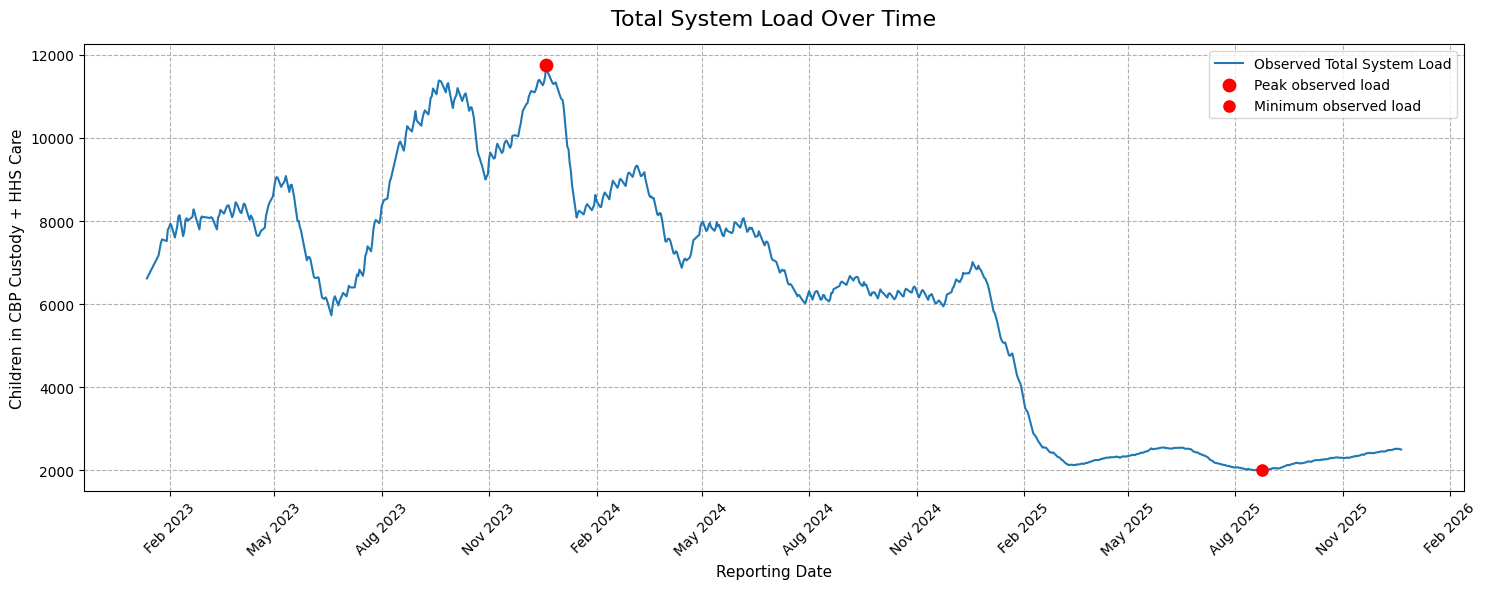


Chart saved to: ..\outputs\figures\01_total_system_load_trend.png


In [41]:

# ============================================================
#  TOTAL SYSTEM LOAD TREND
# ============================================================
import matplotlib.dates as mdates
 

# ------------------------------------------------------------
# 1. Load Phase 2 analytics dataset
# ------------------------------------------------------------
data_path = Path("../data/processed/uac_analytics.csv")

eda_df = pd.read_csv(data_path, parse_dates=["Date"])
eda_df = eda_df.sort_values("Date").reset_index(drop=True)

# ------------------------------------------------------------
# 2. Validate the data before visualization
# ------------------------------------------------------------
required_columns = [
    "Date",
    "Children in CBP custody",
    "Children in HHS Care",
    "Total System Load"
]

missing_columns = [
    col for col in required_columns
    if col not in eda_df.columns
]

if missing_columns:
    raise ValueError(
        f"Required columns are missing: {missing_columns}"
    )

assert len(eda_df) == 720, "Unexpected number of observations."
assert eda_df["Date"].is_unique, "Duplicate reporting dates found."
assert eda_df["Total System Load"].notna().all()

# Verify the load calculation
calculated_load = (
    eda_df["Children in CBP custody"]
    + eda_df["Children in HHS Care"]
)

assert (
    calculated_load == eda_df["Total System Load"]
).all(), "Total System Load formula mismatch."

print("DATA VALIDATION PASSED")
print(f"Observations: {len(eda_df)}")
print(f"Reporting period: {eda_df['Date'].min().date()} "
      f"to {eda_df['Date'].max().date()}")

# ------------------------------------------------------------
# 3. Identify peak and minimum observed load
# ------------------------------------------------------------
peak_row = eda_df.loc[
    eda_df["Total System Load"].idxmax()
]

minimum_row = eda_df.loc[
    eda_df["Total System Load"].idxmin()
]

latest_row = eda_df.iloc[-1]

print("\nKEY OBSERVATIONS")
print(
    f"Peak load: {peak_row['Total System Load']:,.0f} children "
    f"on {peak_row['Date'].date()}"
)
print(
    f"Minimum load: {minimum_row['Total System Load']:,.0f} children "
    f"on {minimum_row['Date'].date()}"
)
print(
    f"Latest load: {latest_row['Total System Load']:,.0f} children "
    f"on {latest_row['Date'].date()}"
)

# ------------------------------------------------------------
# 4. Create the time-series visualization
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(15, 6))

ax.plot(
    eda_df["Date"],
    eda_df["Total System Load"],
    linewidth=1.5,
    label="Observed Total System Load"
)

ax.scatter(
    peak_row["Date"],
    peak_row["Total System Load"],
    s=80,
    marker="o",
    label="Peak observed load",
    zorder=3,
    color="red"
)

ax.scatter(
    minimum_row["Date"],
    minimum_row["Total System Load"],
    s=65,
    marker="o",
    label="Minimum observed load",
    zorder=3,
    color="red"
)

ax.set_title(
    "Total System Load Over Time",
    fontsize=16,
    pad=14
)
ax.set_xlabel("Reporting Date", fontsize=11)
ax.set_ylabel("Children in CBP Custody + HHS Care", fontsize=11)

ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))

ax.grid(True, linestyle="--", alpha=0.35)
ax.legend()
plt.grid(True, linestyle="--", alpha=1)
plt.xticks(rotation=45)
plt.tight_layout()

# Save the chart
chart_dir = Path("../outputs/figures")
chart_dir.mkdir(parents=True, exist_ok=True)

chart_path = chart_dir / "01_total_system_load_trend.png"

fig.savefig(
    chart_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"\nChart saved to: {chart_path}")


COMPONENT VALIDATION PASSED
Mean CBP custody: 171.49
Mean HHS care:    6,061.27
Mean total load:  6,232.77


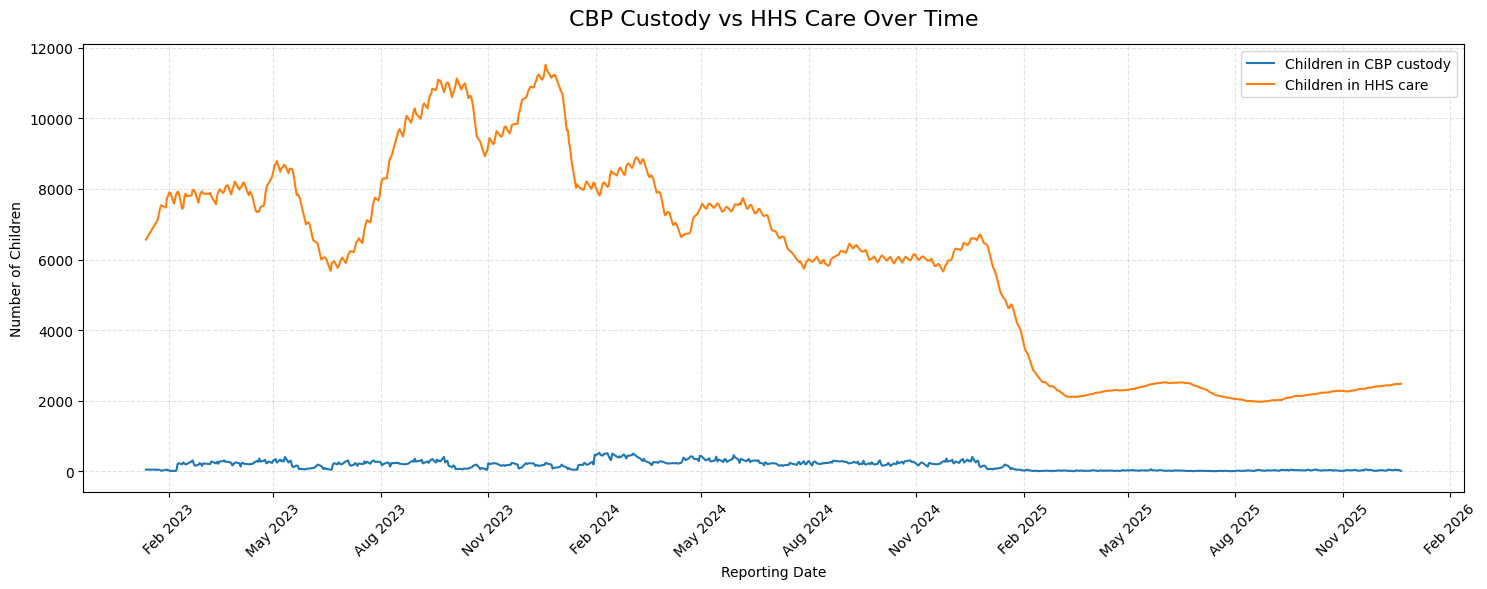

,Component,Mean Children,Median Children,Maximum Observed,Mean Share of Total (%)
0,CBP custody,171.49,193.0,531.0,2.75
1,HHS care,6061.28,6406.5,11516.0,97.25


In [42]:

# ============================================================
# CBP CUSTODY VS HHS CARE
# ============================================================
 
# Reuse eda_df from Step 1
eda_df = eda_df.sort_values("Date").copy()

cbp_col = "Children in CBP custody"
hhs_col = "Children in HHS Care"
load_col = "Total System Load"

# ------------------------------------------------------------
# 1. Validate the component totals
# ------------------------------------------------------------
assert (eda_df[cbp_col] + eda_df[hhs_col] == eda_df[load_col]).all()

print("COMPONENT VALIDATION PASSED")
print(f"Mean CBP custody: {eda_df[cbp_col].mean():,.2f}")
print(f"Mean HHS care:    {eda_df[hhs_col].mean():,.2f}")
print(f"Mean total load:  {eda_df[load_col].mean():,.2f}")

# ------------------------------------------------------------
# 2. Plot both components
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(15, 6))

ax.plot(
    eda_df["Date"], eda_df[cbp_col],
    label="Children in CBP custody",
    linewidth=1.5
)

ax.plot(
    eda_df["Date"], eda_df[hhs_col],
    label="Children in HHS care",
    linewidth=1.5
)

ax.set_title("CBP Custody vs HHS Care Over Time", fontsize=16, pad=14)
ax.set_xlabel("Reporting Date")
ax.set_ylabel("Number of Children")
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.grid(True, linestyle="--", alpha=0.35)
ax.legend()
plt.xticks(rotation=45)
plt.tight_layout()

chart_dir = Path("../outputs/figures")
chart_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    chart_dir / "02_cbp_custody_vs_hhs_care.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 3. Compare average contribution to total load
# ------------------------------------------------------------
component_summary = pd.DataFrame({
    "Component": ["CBP custody", "HHS care"],
    "Mean Children": [
        eda_df[cbp_col].mean(),
        eda_df[hhs_col].mean()
    ],
    "Median Children": [
        eda_df[cbp_col].median(),
        eda_df[hhs_col].median()
    ],
    "Maximum Observed": [
        eda_df[cbp_col].max(),
        eda_df[hhs_col].max()
    ]
})

component_summary["Mean Share of Total (%)"] = [
    100 * eda_df[cbp_col].mean() / eda_df[load_col].mean(),
    100 * eda_df[hhs_col].mean() / eda_df[load_col].mean()
]

display(component_summary.round(2))


 
1. HHS care dominates the combined load.
HHS care accounts for approximately 97.25% of the mean total system load. Consequently, changes in HHS care largely determine the shape of the combined-load trend.
2. CBP custody is much smaller and more variable relative to its scale.
The mean is 171.49 children, with a maximum observed value of 531. This series is difficult to inspect on the same vertical scale as HHS care, so we may later create a separate-scale visualization for CBP.
3. Both components show a substantial change in early 2025.
HHS care falls sharply, while the recorded CBP custody count also becomes very low. This is an important period for further analysis, but the chart alone cannot explain why the decline occurred.
4. The two components should not be interpreted as interchangeable flows.
CBP custody and HHS care are snapshots of different stages of the process. The chart does not independently prove that a reduction in one component caused a reduction in the other.

FLOW VALIDATION PASSED
Mean transfers:  128.67
Mean discharges: 173.41
Mean net pressure: -44.74

Pressure direction:
Positive observations: 238
Negative observations: 475
Zero observations:     7


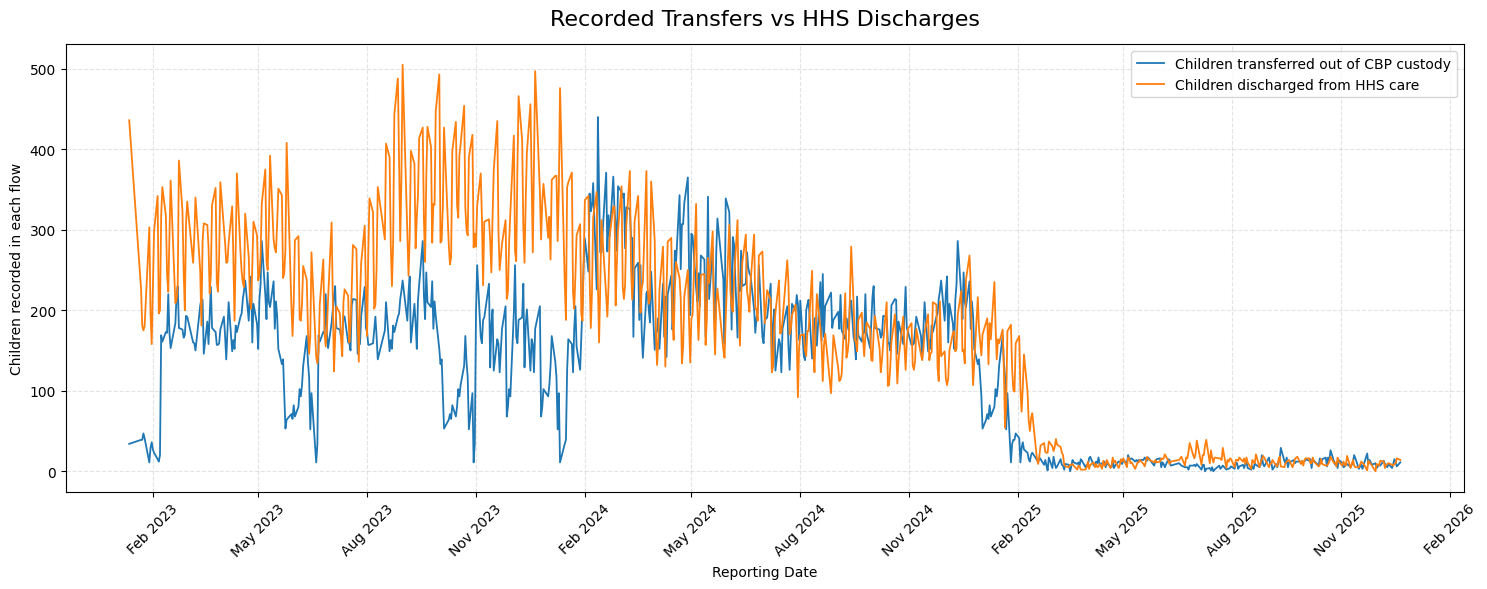

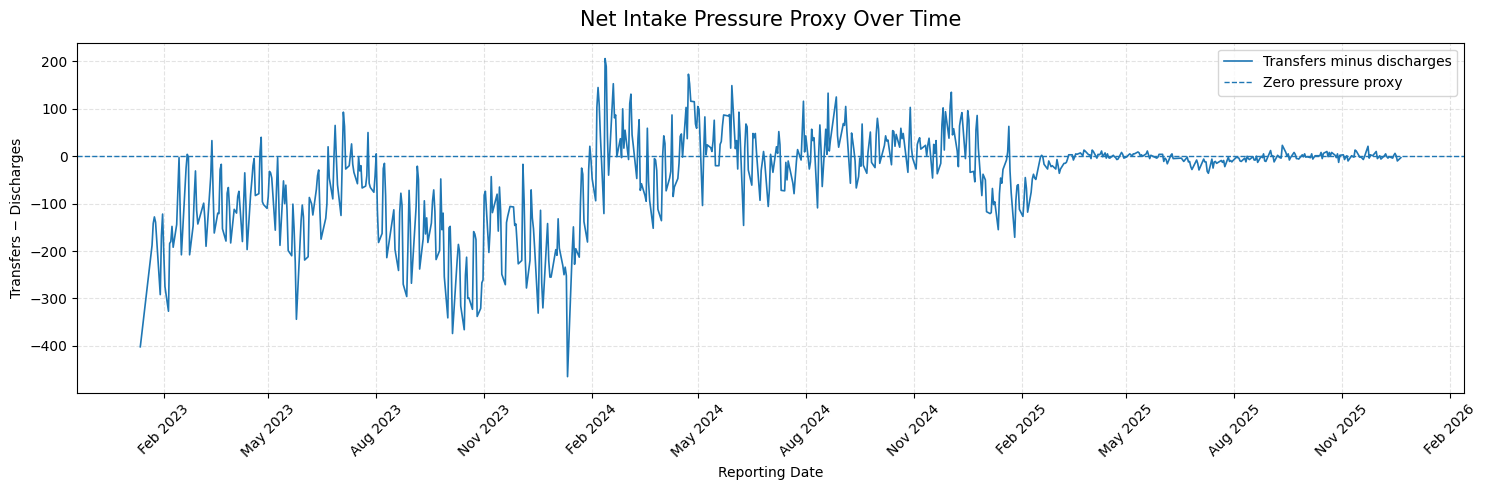

,Maximum pressure observation
Date,2024-02-12 00:00:00
Children transferred out of CBP custody,440.0
Children discharged from HHS Care,234.0
Net Intake Pressure,206.0


,Minimum pressure observation
Date,2024-01-11 00:00:00
Children transferred out of CBP custody,11.0
Children discharged from HHS Care,476.0
Net Intake Pressure,-465.0


In [43]:

# ============================================================
#   TRANSFERS VS DISCHARGES
# ============================================================
 

eda_df = eda_df.sort_values("Date").copy()

transfers_col = "Children transferred out of CBP custody"
discharges_col = "Children discharged from HHS Care"
pressure_col = "Net Intake Pressure"

# ------------------------------------------------------------
# 1. Validate and calculate pressure
# ------------------------------------------------------------
eda_df[pressure_col] = (
    eda_df[transfers_col] - eda_df[discharges_col]
)

assert (
    eda_df[pressure_col]
    == eda_df[transfers_col] - eda_df[discharges_col]
).all()

print("FLOW VALIDATION PASSED")
print(f"Mean transfers:  {eda_df[transfers_col].mean():,.2f}")
print(f"Mean discharges: {eda_df[discharges_col].mean():,.2f}")
print(f"Mean net pressure: {eda_df[pressure_col].mean():,.2f}")

print("\nPressure direction:")
print(f"Positive observations: {(eda_df[pressure_col] > 0).sum()}")
print(f"Negative observations: {(eda_df[pressure_col] < 0).sum()}")
print(f"Zero observations:     {(eda_df[pressure_col] == 0).sum()}")

# ------------------------------------------------------------
# 2. Plot transfers and discharges
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(15, 6))

ax.plot(
    eda_df["Date"],
    eda_df[transfers_col],
    label="Children transferred out of CBP custody",
    linewidth=1.3
)

ax.plot(
    eda_df["Date"],
    eda_df[discharges_col],
    label="Children discharged from HHS care",
    linewidth=1.3
)

ax.set_title("Recorded Transfers vs HHS Discharges", fontsize=16, pad=14)
ax.set_xlabel("Reporting Date")
ax.set_ylabel("Children recorded in each flow")
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.grid(True, linestyle="--", alpha=0.35)
ax.legend()
plt.xticks(rotation=45)
plt.tight_layout()

chart_dir = Path("../outputs/figures")
chart_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    chart_dir / "03_transfers_vs_discharges.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 3. Plot net intake pressure proxy
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(15, 5))

ax.plot(
    eda_df["Date"],
    eda_df[pressure_col],
    linewidth=1.2,
    label="Transfers minus discharges"
)

ax.axhline(0, linestyle="--", linewidth=1, label="Zero pressure proxy")

ax.set_title("Net Intake Pressure Proxy Over Time", fontsize=15, pad=12)
ax.set_xlabel("Reporting Date")
ax.set_ylabel("Transfers − Discharges")
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.grid(True, linestyle="--", alpha=0.35)
ax.legend()
plt.xticks(rotation=45)
plt.tight_layout()

fig.savefig(
    chart_dir / "04_net_intake_pressure.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 4. Identify extreme observations for investigation
# ------------------------------------------------------------
display(
    eda_df.loc[
        eda_df[pressure_col].idxmax(),
        ["Date", transfers_col, discharges_col, pressure_col]
    ].to_frame("Maximum pressure observation")
)

display(
    eda_df.loc[
        eda_df[pressure_col].idxmin(),
        ["Date", transfers_col, discharges_col, pressure_col]
    ].to_frame("Minimum pressure observation")
)


MONTHLY SUMMARY CREATED
Months with observations: 36
Monthly date range: 2023-01-01 to 2025-12-01


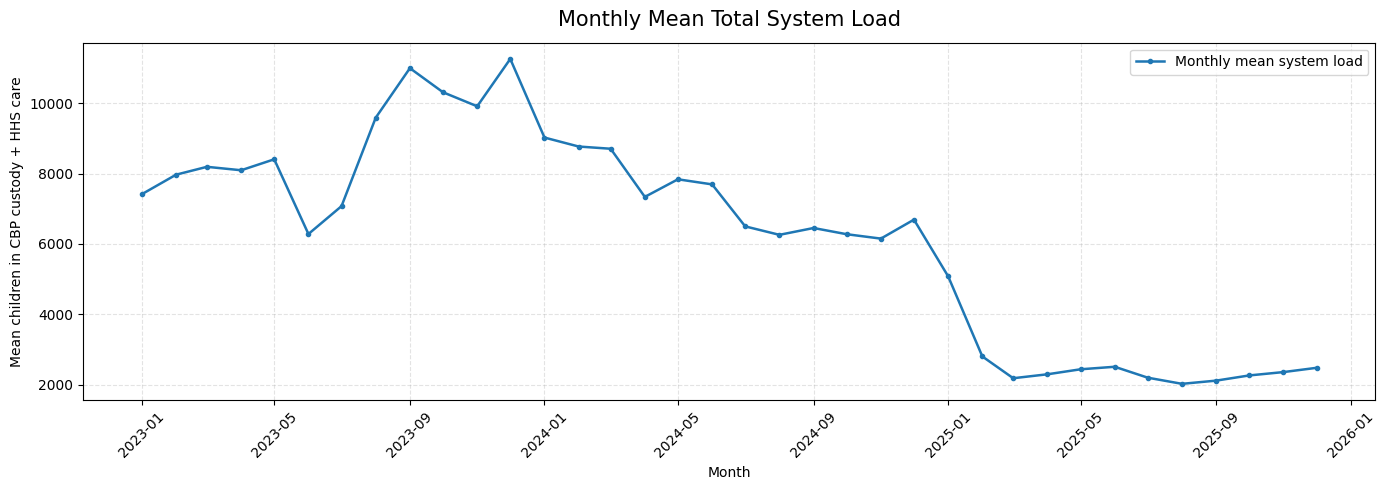

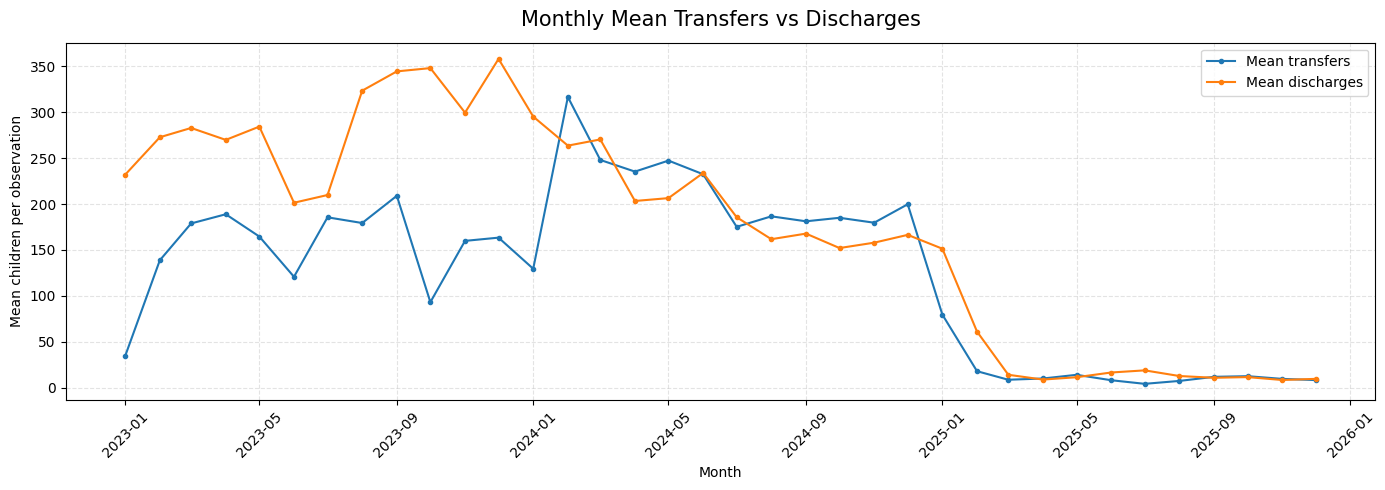

,Month,Observations,Mean_System_Load,Minimum_System_Load,Maximum_System_Load,Mean_CBP_Custody,Mean_HHS_Care,Mean_Transfers,Mean_Discharges,Mean_Net_Pressure,Year
24,2025-01-01,22,5080.05,3965.0,6471.0,88.95,4991.09,79.55,151.36,-71.82,2025
25,2025-02-01,19,2804.21,2406.0,3505.0,22.68,2781.53,17.95,61.05,-43.11,2025
26,2025-03-01,22,2185.91,2125.0,2321.0,21.45,2164.45,8.64,14.05,-5.41,2025
27,2025-04-01,23,2298.00,2227.0,2343.0,24.87,2273.13,10.00,8.83,1.17,2025
28,2025-05-01,18,2439.78,2338.0,2544.0,32.83,2406.94,14.00,11.39,2.61,2025
29,2025-06-01,17,2511.47,2429.0,2552.0,19.06,2492.41,8.12,16.53,-8.41,2025
30,2025-07-01,21,2201.14,2067.0,2405.0,13.95,2187.19,4.19,18.86,-14.67,2025
31,2025-08-01,20,2026.90,2002.0,2075.0,25.60,2001.30,7.35,12.70,-5.35,2025
32,2025-09-01,22,2118.05,2039.0,2191.0,35.82,2082.23,11.82,10.77,1.05,2025
33,2025-10-01,21,2265.38,2196.0,2313.0,34.33,2231.05,12.52,11.52,1.00,2025


,Year,Months_With_Observations,Mean_Monthly_System_Load,Mean_Monthly_Transfers,Mean_Monthly_Discharges
0,2023,12.0,8789.51,151.41,285.59
1,2024,12.0,7307.03,209.74,205.39
2,2025,12.0,2564.42,16.00,27.92



Saved: ../outputs/eda_monthly_trend_summary.csv


In [44]:

# ============================================================
#  MONTHLY TREND ANALYSIS
# ============================================================

 

eda_df = eda_df.sort_values("Date").copy()
eda_df["Month"] = eda_df["Date"].dt.to_period("M").dt.to_timestamp()

# ------------------------------------------------------------
# 1. Monthly aggregation
# ------------------------------------------------------------
monthly_eda = (
    eda_df.groupby("Month")
    .agg(
        Observations=("Total System Load", "count"),
        Mean_System_Load=("Total System Load", "mean"),
        Minimum_System_Load=("Total System Load", "min"),
        Maximum_System_Load=("Total System Load", "max"),
        Mean_CBP_Custody=("Children in CBP custody", "mean"),
        Mean_HHS_Care=("Children in HHS Care", "mean"),
        Mean_Transfers=(
            "Children transferred out of CBP custody", "mean"
        ),
        Mean_Discharges=(
            "Children discharged from HHS Care", "mean"
        ),
        Mean_Net_Pressure=("Net Intake Pressure", "mean")
    )
    .reset_index()
)

# Important: months with no observations are not created or filled with zero.

print("MONTHLY SUMMARY CREATED")
print(f"Months with observations: {len(monthly_eda)}")
print(f"Monthly date range: {monthly_eda['Month'].min().date()} "
      f"to {monthly_eda['Month'].max().date()}")

# ------------------------------------------------------------
# 2. Plot monthly mean system load
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(
    monthly_eda["Month"],
    monthly_eda["Mean_System_Load"],
    marker="o",
    markersize=3,
    linewidth=1.8,
    label="Monthly mean system load"
)

ax.set_title("Monthly Mean Total System Load", fontsize=15, pad=12)
ax.set_xlabel("Month")
ax.set_ylabel("Mean children in CBP custody + HHS care")
ax.grid(True, linestyle="--", alpha=0.35)
ax.legend()
plt.xticks(rotation=45)
plt.tight_layout()

figure_dir = Path("../outputs/figures")
figure_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    figure_dir / "05_monthly_mean_system_load.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 3. Plot monthly mean transfers and discharges
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(
    monthly_eda["Month"],
    monthly_eda["Mean_Transfers"],
    marker="o",
    markersize=3,
    label="Mean transfers"
)

ax.plot(
    monthly_eda["Month"],
    monthly_eda["Mean_Discharges"],
    marker="o",
    markersize=3,
    label="Mean discharges"
)

ax.set_title("Monthly Mean Transfers vs Discharges", fontsize=15, pad=12)
ax.set_xlabel("Month")
ax.set_ylabel("Mean children per observation")
ax.grid(True, linestyle="--", alpha=0.35)
ax.legend()
plt.xticks(rotation=45)
plt.tight_layout()

fig.savefig(
    figure_dir / "06_monthly_mean_flows.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 4. Compare selected periods
# ------------------------------------------------------------
monthly_eda["Year"] = monthly_eda["Month"].dt.year

annual_summary = (
    monthly_eda.groupby("Year")
    .apply(
        lambda group: pd.Series({
            "Months_With_Observations": len(group),
            "Mean_Monthly_System_Load": group["Mean_System_Load"].mean(),
            "Mean_Monthly_Transfers": group["Mean_Transfers"].mean(),
            "Mean_Monthly_Discharges": group["Mean_Discharges"].mean()
        }),
        include_groups=False
    )
    .reset_index()
)

display(monthly_eda.tail(12).round(2))
display(annual_summary.round(2))

# Export the monthly EDA table
output_dir = Path("../outputs")
output_dir.mkdir(parents=True, exist_ok=True)

monthly_eda.to_csv(
    output_dir / "eda_monthly_trend_summary.csv",
    index=False
)

print("\nSaved: ../outputs/eda_monthly_trend_summary.csv")


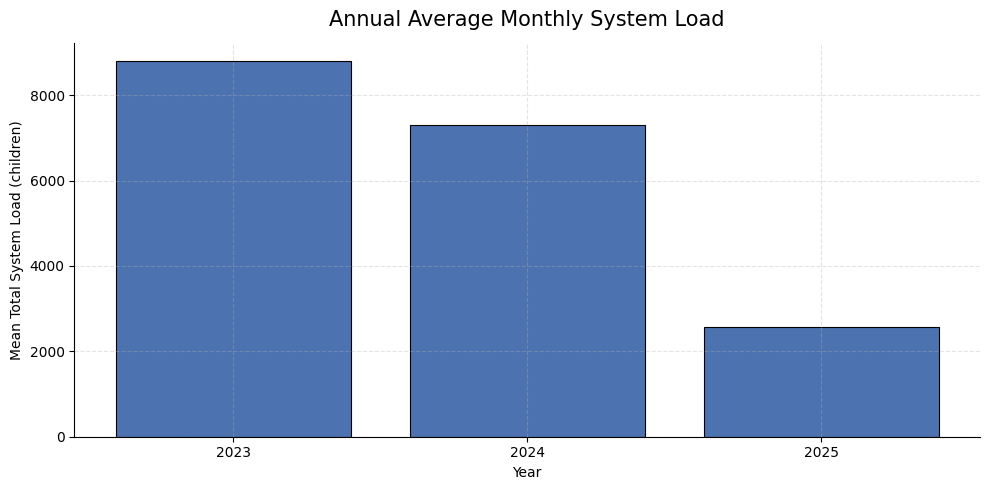


Saved: ../outputs/yearly_trend_summary.csv


In [45]:
# ============================================================
# ANNUAL SUMMARY CHART
# ============================================================

# Build annual summary if it is not already available
if "annual_summary" not in globals():
    annual_summary = (
        monthly_eda.assign(Year=monthly_eda["Month"].dt.year)
        .groupby("Year")
        .apply(
            lambda group: pd.Series({
                "Months_With_Observations": len(group),
                "Mean_Monthly_System_Load": group["Mean_System_Load"].mean(),
                "Mean_Monthly_Transfers": group["Mean_Transfers"].mean(),
                "Mean_Monthly_Discharges": group["Mean_Discharges"].mean()
            }),
            include_groups=False
        )
        .reset_index()
    )

annual_plot = annual_summary.copy()
annual_plot["Year"] = annual_plot["Year"].astype(int)

fig, ax = plt.subplots(figsize=(10, 5))

ax.bar(
    annual_plot["Year"],
    annual_plot["Mean_Monthly_System_Load"],
    color="#4C72B0",
    edgecolor="black",
    linewidth=0.8
)

ax.set_title("Annual Average Monthly System Load", fontsize=15, pad=12)
ax.set_xlabel("Year")
ax.set_ylabel("Mean Total System Load (children)")
ax.grid(True, linestyle="--", alpha=0.35)
ax.set_xticks(annual_plot["Year"])

for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)

plt.tight_layout()

chart_dir = Path("../outputs/figures")
chart_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(chart_dir / "07_annual_average_monthly_system_load.png", dpi=300, bbox_inches="tight")

plt.show()

fig.savefig(
    chart_dir / "05_yearly_trend_summary.png",
    dpi=300,
    bbox_inches="tight"
)
print("\nSaved: ../outputs/yearly_trend_summary.csv")


LARGEST INCREASE IN MONTHLY MEAN SYSTEM LOAD
Month: August 2023
Change: 35.51%
Previous-to-current change: 2,511.72

LARGEST DECREASE IN MONTHLY MEAN SYSTEM LOAD
Month: February 2025
Change: -44.80%
Previous-to-current change: -2,275.83


,Month,Observations,Mean_System_Load,Load Change,Load Change (%),Mean_Transfers,Transfer Change (%),Mean_Discharges,Discharge Change (%)
21,2024-10-01,21,6276.29,-176.35,-2.73,185.05,2.11,152.10,-9.37
22,2024-11-01,19,6151.42,-124.86,-1.99,179.68,-2.90,157.95,3.85
23,2024-12-01,22,6690.41,538.99,8.76,199.77,11.18,166.45,5.39
24,2025-01-01,22,5080.05,-1610.36,-24.07,79.55,-60.18,151.36,-9.07
25,2025-02-01,19,2804.21,-2275.83,-44.80,17.95,-77.44,61.05,-59.66
26,2025-03-01,22,2185.91,-618.30,-22.05,8.64,-51.88,14.05,-76.99
27,2025-04-01,23,2298.00,112.09,5.13,10.00,15.79,8.83,-37.16
28,2025-05-01,18,2439.78,141.78,6.17,14.00,40.00,11.39,29.04
29,2025-06-01,17,2511.47,71.69,2.94,8.12,-42.02,16.53,45.14


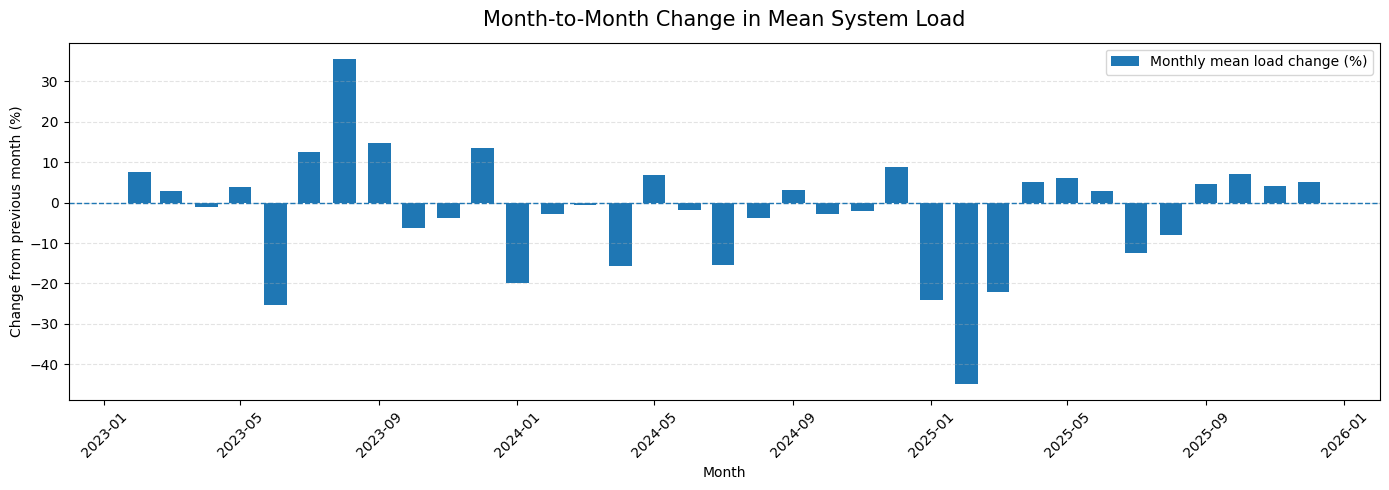


Saved: ../outputs/eda_monthly_change_analysis.csv


In [46]:

# ============================================================
# MONTH-TO-MONTH CHANGE ANALYSIS
# ============================================================
 

# Reuse monthly_eda from Step 4
monthly_change = monthly_eda.sort_values("Month").copy()

# Month-to-month changes in monthly mean load
monthly_change["Load Change"] = (
    monthly_change["Mean_System_Load"].diff()
)

monthly_change["Load Change (%)"] = (
    monthly_change["Mean_System_Load"].pct_change() * 100
)

# Month-to-month changes in mean recorded flows
monthly_change["Transfer Change (%)"] = (
    monthly_change["Mean_Transfers"].pct_change() * 100
)

monthly_change["Discharge Change (%)"] = (
    monthly_change["Mean_Discharges"].pct_change() * 100
)

# ------------------------------------------------------------
# 1. Largest monthly increases and decreases
# ------------------------------------------------------------
valid_changes = monthly_change.dropna(
    subset=["Load Change (%)"]
)

largest_increase = valid_changes.loc[
    valid_changes["Load Change (%)"].idxmax()
]

largest_decrease = valid_changes.loc[
    valid_changes["Load Change (%)"].idxmin()
]

print("LARGEST INCREASE IN MONTHLY MEAN SYSTEM LOAD")
print(f"Month: {largest_increase['Month'].strftime('%B %Y')}")
print(f"Change: {largest_increase['Load Change (%)']:.2f}%")
print(f"Previous-to-current change: "
      f"{largest_increase['Load Change']:,.2f}")

print("\nLARGEST DECREASE IN MONTHLY MEAN SYSTEM LOAD")
print(f"Month: {largest_decrease['Month'].strftime('%B %Y')}")
print(f"Change: {largest_decrease['Load Change (%)']:.2f}%")
print(f"Previous-to-current change: "
      f"{largest_decrease['Load Change']:,.2f}")

# ------------------------------------------------------------
# 2. Display the key transition months
# ------------------------------------------------------------
transition = monthly_change[
    monthly_change["Month"].between(
        pd.Timestamp("2024-10-01"),
        pd.Timestamp("2025-06-01")
    )
][[
    "Month",
    "Observations",
    "Mean_System_Load",
    "Load Change",
    "Load Change (%)",
    "Mean_Transfers",
    "Transfer Change (%)",
    "Mean_Discharges",
    "Discharge Change (%)"
]]

display(transition.round(2))

# ------------------------------------------------------------
# 3. Plot month-to-month load percentage changes
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(14, 5))

ax.bar(
    monthly_change["Month"],
    monthly_change["Load Change (%)"],
    width=20,
    label="Monthly mean load change (%)"
)

ax.axhline(0, linestyle="--", linewidth=1)

ax.set_title(
    "Month-to-Month Change in Mean System Load",
    fontsize=15,
    pad=12
)
ax.set_xlabel("Month")
ax.set_ylabel("Change from previous month (%)")
ax.grid(True, axis="y", linestyle="--", alpha=0.35)
ax.legend()
plt.xticks(rotation=45)
plt.tight_layout()

figure_dir = Path("../outputs/figures")
figure_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    figure_dir / "07_monthly_system_load_change.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 4. Save the change-analysis table
# ------------------------------------------------------------
output_dir = Path("../outputs")
output_dir.mkdir(parents=True, exist_ok=True)

monthly_change.to_csv(
    output_dir / "eda_monthly_change_analysis.csv",
    index=False
)

print("\nSaved: ../outputs/eda_monthly_change_analysis.csv")


PRESSURE DATA VALIDATION PASSED
Total observations: 720
Repeated-pressure observations: 178
Repeated-pressure frequency: 24.72%

FIRST 15 FLAGGED OBSERVATIONS


,Date,Total System Load,Net Intake Pressure,Positive Pressure Count - 7D,Observation Count - 7D
114,2023-07-10,6585.0,3.0,3.0,5.0
115,2023-07-11,6714.0,26.0,3.0,5.0
256,2024-02-07,8613.0,108.0,3.0,5.0
257,2024-02-08,8687.0,43.0,4.0,5.0
259,2024-02-12,8522.0,206.0,4.0,5.0
260,2024-02-13,8717.0,189.0,4.0,5.0
261,2024-02-14,8834.0,42.0,4.0,5.0
263,2024-02-19,8800.0,153.0,3.0,4.0
264,2024-02-20,8883.0,81.0,3.0,4.0
265,2024-02-21,9003.0,87.0,3.0,4.0



TOP 10 REPEATED-PRESSURE EPISODES


,Episode ID,Start_Date,End_Date,Flagged_Observations,Mean_Net_Pressure,Maximum_Net_Pressure,Mean_System_Load,Calendar Span (Days)
29,30,2024-11-25,2024-12-12,13,69.69,135.0,6419.08,18
32,33,2025-03-19,2025-04-03,11,6.73,13.0,2185.27,16
39,40,2025-10-14,2025-11-05,11,4.91,10.0,2292.91,23
7,8,2024-04-21,2024-05-02,10,102.80,173.0,7596.60,12
10,11,2024-05-27,2024-06-06,8,65.62,149.0,7902.00,11
24,25,2024-10-14,2024-10-23,8,42.00,59.0,6258.88,10
8,9,2024-05-06,2024-05-15,8,31.50,83.0,7866.50,10
33,34,2025-04-07,2025-04-15,6,5.83,11.0,2285.00,9
34,35,2025-05-07,2025-05-14,6,5.00,9.0,2404.50,8
17,18,2024-08-18,2024-08-22,5,47.80,133.0,6217.40,5


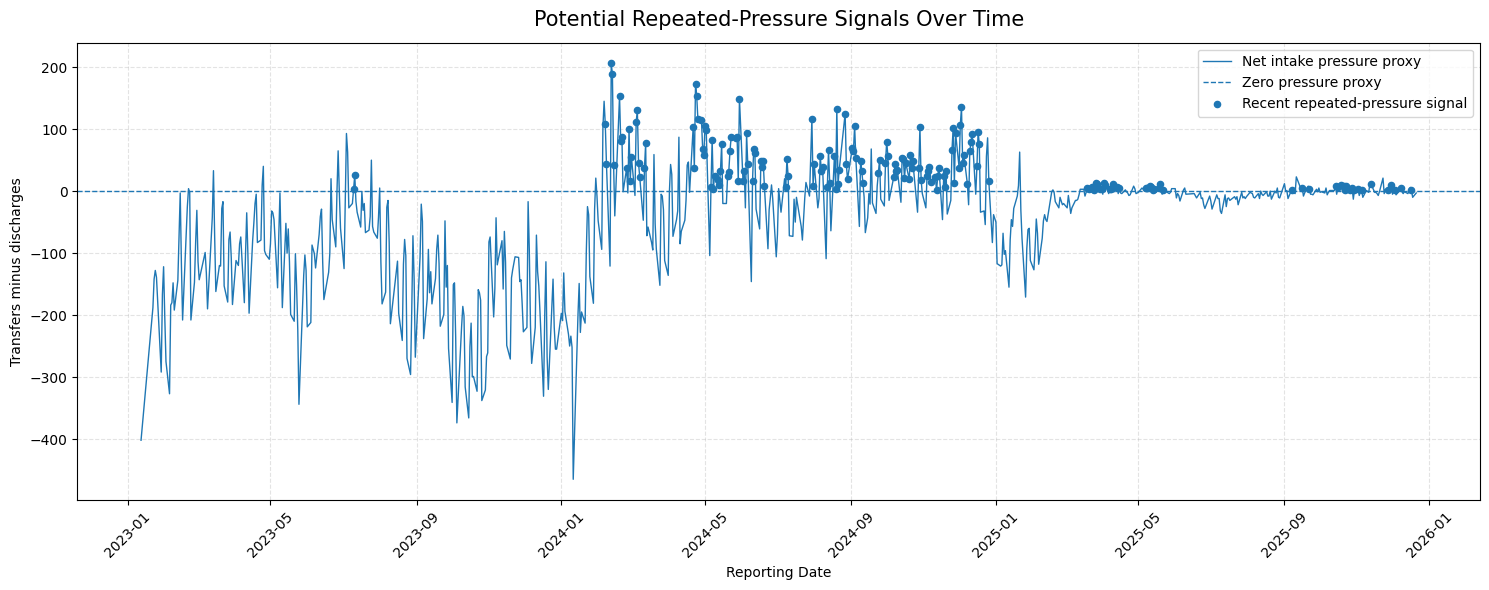


Saved:
../outputs/pressure_flagged_observations.csv
../outputs/pressure_episodes.csv
../outputs/figures/08_repeated_pressure_signals.png


In [47]:

# ============================================================
#  HIGH-PRESSURE PERIOD ANALYSIS
# ============================================================
 
# ------------------------------------------------------------
# 1. Load the engineered dataset
# ------------------------------------------------------------
data_path = Path("../data/processed/uac_analytics.csv")

pressure_df = pd.read_csv(data_path, parse_dates=["Date"])
pressure_df = pressure_df.sort_values("Date").reset_index(drop=True)

required_columns = [
    "Date",
    "Total System Load",
    "Net Intake Pressure",
    "Recent Repeated Pressure",
    "Positive Pressure Count - 7D",
    "Observation Count - 7D"
]

missing = [
    col for col in required_columns
    if col not in pressure_df.columns
]

if missing:
    raise ValueError(f"Missing required columns: {missing}")

# Ensure the pressure flag is Boolean
if pressure_df["Recent Repeated Pressure"].dtype != bool:
    pressure_df["Recent Repeated Pressure"] = (
        pressure_df["Recent Repeated Pressure"]
        .astype(str)
        .str.strip()
        .str.lower()
        .map({"true": True, "false": False})
    )

if pressure_df["Recent Repeated Pressure"].isna().any():
    raise ValueError("Pressure flag contains missing or invalid values.")

assert len(pressure_df) == 720
assert pressure_df["Date"].is_unique

# Verify the flag's current-pressure condition
flagged = pressure_df["Recent Repeated Pressure"]

assert (
    pressure_df.loc[flagged, "Net Intake Pressure"] > 0
).all()

print("PRESSURE DATA VALIDATION PASSED")
print(f"Total observations: {len(pressure_df)}")
print(f"Repeated-pressure observations: {int(flagged.sum())}")
print(f"Repeated-pressure frequency: {flagged.mean() * 100:.2f}%")

# ------------------------------------------------------------
# 2. Identify individual flagged dates
# ------------------------------------------------------------
pressure_dates = pressure_df.loc[
    flagged,
    [
        "Date",
        "Total System Load",
        "Net Intake Pressure",
        "Positive Pressure Count - 7D",
        "Observation Count - 7D"
    ]
].copy()

print("\nFIRST 15 FLAGGED OBSERVATIONS")
display(pressure_dates.head(15))

# ------------------------------------------------------------
# 3. Group consecutive flagged reporting observations
#    into episodes, allowing gaps of up to 3 calendar days.
# ------------------------------------------------------------
# This is a reporting-date episode definition, not proof that
# pressure persisted continuously on unobserved dates.

pressure_dates = pressure_dates.sort_values("Date").reset_index(drop=True)

if len(pressure_dates) > 0:
    pressure_dates["Gap Since Previous Flag (Days)"] = (
        pressure_dates["Date"].diff().dt.days
    )

    pressure_dates["New Episode"] = (
        pressure_dates["Gap Since Previous Flag (Days)"].isna()
        | (pressure_dates["Gap Since Previous Flag (Days)"] > 3)
    )

    pressure_dates["Episode ID"] = (
        pressure_dates["New Episode"].cumsum()
    )

    episodes = (
        pressure_dates.groupby("Episode ID")
        .agg(
            Start_Date=("Date", "min"),
            End_Date=("Date", "max"),
            Flagged_Observations=("Date", "count"),
            Mean_Net_Pressure=("Net Intake Pressure", "mean"),
            Maximum_Net_Pressure=("Net Intake Pressure", "max"),
            Mean_System_Load=("Total System Load", "mean")
        )
        .reset_index()
    )

    episodes["Calendar Span (Days)"] = (
        episodes["End_Date"] - episodes["Start_Date"]
    ).dt.days + 1

    episodes = episodes.sort_values(
        ["Flagged_Observations", "Mean_Net_Pressure"],
        ascending=[False, False]
    )

    print("\nTOP 10 REPEATED-PRESSURE EPISODES")
    display(episodes.head(10).round(2))

else:
    episodes = pd.DataFrame()
    print("No repeated-pressure observations found.")

# ------------------------------------------------------------
# 4. Plot net pressure and highlight flagged dates
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(15, 6))

ax.plot(
    pressure_df["Date"],
    pressure_df["Net Intake Pressure"],
    linewidth=1,
    label="Net intake pressure proxy"
)

ax.axhline(
    0,
    linestyle="--",
    linewidth=1,
    label="Zero pressure proxy"
)

ax.scatter(
    pressure_df.loc[flagged, "Date"],
    pressure_df.loc[flagged, "Net Intake Pressure"],
    s=20,
    label="Recent repeated-pressure signal",
    zorder=3
)

ax.set_title(
    "Potential Repeated-Pressure Signals Over Time",
    fontsize=15,
    pad=12
)
ax.set_xlabel("Reporting Date")
ax.set_ylabel("Transfers minus discharges")
ax.grid(True, linestyle="--", alpha=0.35)
ax.legend()
plt.xticks(rotation=45)
plt.tight_layout()

figure_dir = Path("../outputs/figures")
figure_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    figure_dir / "08_repeated_pressure_signals.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 5. Export episode analysis
# ------------------------------------------------------------
output_dir = Path("../outputs")
output_dir.mkdir(parents=True, exist_ok=True)

pressure_dates.to_csv(
    output_dir / "pressure_flagged_observations.csv",
    index=False
)

episodes.to_csv(
    output_dir / "pressure_episodes.csv",
    index=False
)

print("\nSaved:")
print("../outputs/pressure_flagged_observations.csv")
print("../outputs/pressure_episodes.csv")
print("../outputs/figures/08_repeated_pressure_signals.png")


In [48]:

# ============================================================
#  YEARLY PRESSURE AND LOAD COMPARISON
 

df = pd.read_csv(
    "../data/processed/uac_analytics.csv",
    parse_dates=["Date"]
).sort_values("Date").reset_index(drop=True)

required = [
    "Date",
    "Total System Load",
    "Children in CBP custody",
    "Children in HHS Care",
    "Net Intake Pressure",
    "Recent Repeated Pressure"
]

missing = [c for c in required if c not in df.columns]
if missing:
    raise ValueError(f"Missing required columns: {missing}")

# Normalize the flag if CSV loading represented it as text.
if df["Recent Repeated Pressure"].dtype != bool:
    df["Recent Repeated Pressure"] = (
        df["Recent Repeated Pressure"].astype(str).str.lower()
        .map({"true": True, "false": False})
    )

if df["Recent Repeated Pressure"].isna().any():
    raise ValueError("Invalid values found in pressure flag.")

df["Year"] = df["Date"].dt.year
df["Pressure Flag"] = df["Recent Repeated Pressure"]

# ------------------------------------------------------------
# 1. Yearly summary
# ------------------------------------------------------------
yearly = (
    df.groupby("Year")
    .agg(
        Observations=("Date", "count"),
        Mean_System_Load=("Total System Load", "mean"),
        Median_System_Load=("Total System Load", "median"),
        Mean_CBP_Custody=("Children in CBP custody", "mean"),
        Mean_HHS_Care=("Children in HHS Care", "mean"),
        Mean_Net_Pressure=("Net Intake Pressure", "mean"),
        Positive_Pressure_Observations=(
            "Net Intake Pressure", lambda s: int((s > 0).sum())
        ),
        Repeated_Pressure_Observations=("Pressure Flag", "sum")
    )
    .reset_index()
)

yearly["Positive Pressure (%)"] = (
    100 * yearly["Positive_Pressure_Observations"]
    / yearly["Observations"]
)

yearly["Repeated Pressure (%)"] = (
    100 * yearly["Repeated_Pressure_Observations"]
    / yearly["Observations"]
)

print("YEARLY PRESSURE AND LOAD SUMMARY")
display(yearly.round(2))

# ------------------------------------------------------------
# 2. Compare load on flagged vs unflagged dates
# ------------------------------------------------------------
df["Pressure Group"] = df["Pressure Flag"].map({
    True: "Repeated-pressure flagged",
    False: "Not flagged"
})

group_comparison = (
    df.groupby("Pressure Group")
    .agg(
        Observations=("Date", "count"),
        Mean_System_Load=("Total System Load", "mean"),
        Median_System_Load=("Total System Load", "median"),
        Mean_CBP_Custody=("Children in CBP custody", "mean"),
        Mean_HHS_Care=("Children in HHS Care", "mean"),
        Mean_Net_Pressure=("Net Intake Pressure", "mean")
    )
    .reset_index()
)

print("\nFLAGGED VS UNFLAGGED OBSERVATIONS")
display(group_comparison.round(2))

# ------------------------------------------------------------
# 3. Export results
# ------------------------------------------------------------
out = Path("../outputs")
out.mkdir(parents=True, exist_ok=True)

yearly.to_csv(out / "yearly_pressure_load_comparison.csv", index=False)
group_comparison.to_csv(
    out / "flagged_vs_unflagged_load_comparison.csv",
    index=False
)

# Validation
assert int(yearly["Observations"].sum()) == len(df)
assert int(yearly["Repeated_Pressure_Observations"].sum()) == int(
    df["Pressure Flag"].sum()
)

print("\nVALIDATION PASSED")
print("Saved:")
print("../outputs/yearly_pressure_load_comparison.csv")
print("../outputs/flagged_vs_unflagged_load_comparison.csv")


YEARLY PRESSURE AND LOAD SUMMARY


,Year,Observations,Mean_System_Load,Median_System_Load,Mean_CBP_Custody,Mean_HHS_Care,Mean_Net_Pressure,Positive_Pressure_Observations,Repeated_Pressure_Observations,Positive Pressure (%),Repeated Pressure (%)
0,2023,230,8846.54,8437.0,200.47,8646.07,-130.96,12,2,5.22,0.87
1,2024,251,7319.86,7055.0,276.90,7042.96,3.44,148,130,58.96,51.79
2,2025,239,2575.74,2320.0,32.91,2542.84,-12.36,78,46,32.64,19.25



FLAGGED VS UNFLAGGED OBSERVATIONS


,Pressure Group,Observations,Mean_System_Load,Median_System_Load,Mean_CBP_Custody,Mean_HHS_Care,Mean_Net_Pressure
0,Not flagged,542,6350.46,7033.0,152.48,6197.98,-73.62
1,Repeated-pressure flagged,178,5874.42,6322.0,229.39,5645.03,43.20



VALIDATION PASSED
Saved:
../outputs/yearly_pressure_load_comparison.csv
../outputs/flagged_vs_unflagged_load_comparison.csv


PRESSURE-LOAD ASSOCIATION
Pearson correlation:  -0.4622
Spearman correlation: -0.4452

YEARLY CORRELATIONS


,Year,Observations,Pearson_Correlation,Spearman_Correlation
0,2023,230.0,-0.4338,-0.4190
1,2024,251.0,-0.2910,-0.1292
2,2025,239.0,-0.6959,-0.2709


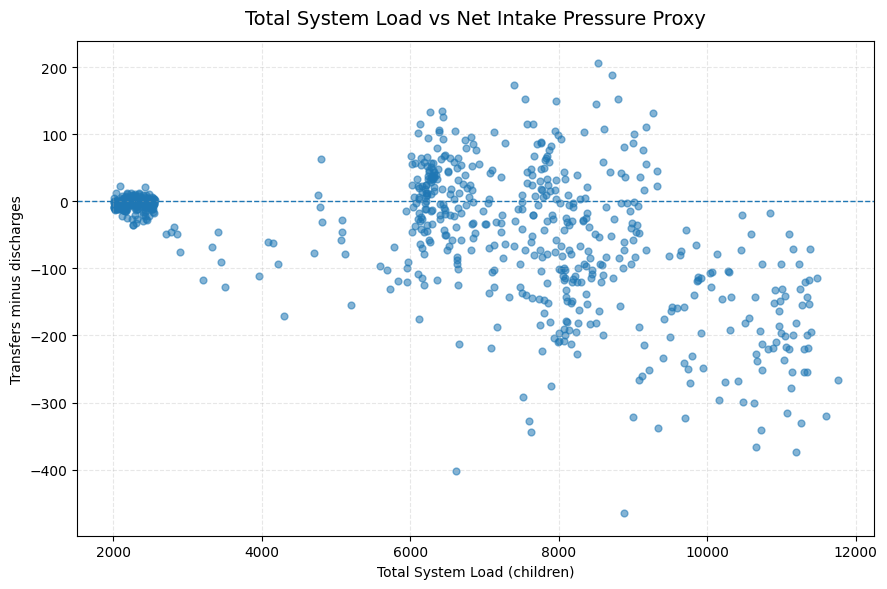


VALIDATION PASSED
Saved: ../outputs/pressure_load_correlation_by_year.csv
Saved: ../outputs/figures/09_pressure_load_scatter.png


In [49]:

# ============================================================
#  : PRESSURE-LOAD ASSOCIATION
# ============================================================



df = pd.read_csv(
    "../data/processed/uac_analytics.csv",
    parse_dates=["Date"]
).sort_values("Date").reset_index(drop=True)

load_col = "Total System Load"
pressure_col = "Net Intake Pressure"

# Validate required fields
assert df[load_col].notna().all()
assert df[pressure_col].notna().all()
assert len(df) == 720
assert df["Date"].is_unique

# ------------------------------------------------------------
# 1. Overall correlations
# ------------------------------------------------------------
pearson_r = df[load_col].corr(df[pressure_col], method="pearson")
spearman_r = df[load_col].corr(df[pressure_col], method="spearman")

print("PRESSURE-LOAD ASSOCIATION")
print(f"Pearson correlation:  {pearson_r:.4f}")
print(f"Spearman correlation: {spearman_r:.4f}")

# ------------------------------------------------------------
# 2. Correlations by year
# ------------------------------------------------------------
df["Year"] = df["Date"].dt.year

yearly_corr = (
    df.groupby("Year")
    .apply(
        lambda g: pd.Series({
            "Observations": len(g),
            "Pearson_Correlation": g[load_col].corr(
                g[pressure_col], method="pearson"
            ),
            "Spearman_Correlation": g[load_col].corr(
                g[pressure_col], method="spearman"
            )
        }),
        include_groups=False
    )
    .reset_index()
)

print("\nYEARLY CORRELATIONS")
display(yearly_corr.round(4))

# ------------------------------------------------------------
# 3. Scatter plot
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 6))

ax.scatter(
    df[load_col],
    df[pressure_col],
    alpha=0.55,
    s=24
)

ax.axhline(0, linestyle="--", linewidth=1)

ax.set_title(
    "Total System Load vs Net Intake Pressure Proxy",
    fontsize=14,
    pad=12
)
ax.set_xlabel("Total System Load (children)")
ax.set_ylabel("Transfers minus discharges")
ax.grid(True, linestyle="--", alpha=0.3)
plt.tight_layout()

figure_dir = Path("../outputs/figures")
figure_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    figure_dir / "09_pressure_load_scatter.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 4. Export results
# ------------------------------------------------------------
output_dir = Path("../outputs")
output_dir.mkdir(parents=True, exist_ok=True)

yearly_corr.to_csv(
    output_dir / "pressure_load_correlation_by_year.csv",
    index=False
)

print("\nVALIDATION PASSED")
print("Saved: ../outputs/pressure_load_correlation_by_year.csv")
print("Saved: ../outputs/figures/09_pressure_load_scatter.png")


Model Building

FORECAST DATA CHECK
Original observed records: 720
Unobserved calendar dates interpolated: 355
Daily modelling records: 1075
Start: 2023-01-12
End: 2025-12-21

TRAINING OBSERVATIONS: 837
TEST OBSERVATIONS: 210
Test begins: 2025-05-26

FORECAST MODEL COMPARISON


,Model,MAE,RMSE
0,Previous-day baseline,7.61,9.61
1,Random Forest,36.05,57.50


Random Forest MAE improvement vs baseline: -373.85%


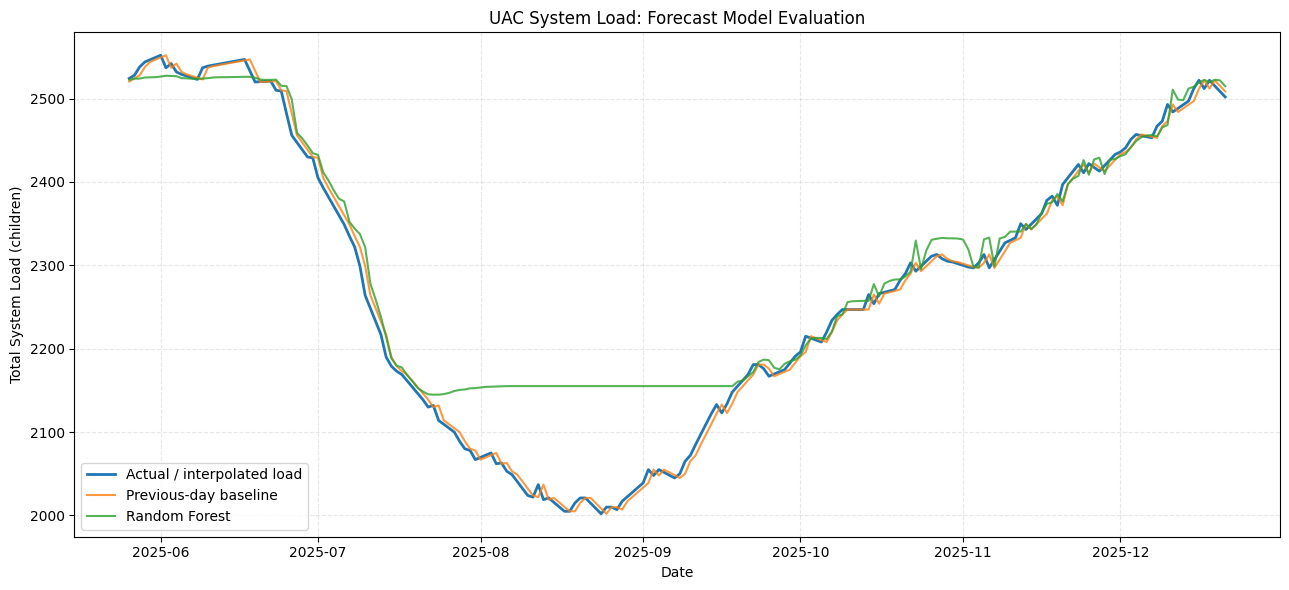


OUTPUT VALIDATION
FOUND: ..\outputs\forecast_test_predictions.csv
FOUND: ..\outputs\forecast_model_comparison.csv
FOUND: ..\outputs\figures\10_forecast_model_evaluation.png

FORECASTING EXPERIMENT FINISHED


In [50]:

# ============================================================
#  SYSTEM LOAD FORECASTING
# Baseline vs Random Forest
# ============================================================
 
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

# ------------------------------------------------------------
# 1. LOAD AND VALIDATE DATA
# ------------------------------------------------------------

data_path = Path("../data/processed/uac_analytics.csv")
output_dir = Path("../outputs")
figure_dir = output_dir / "figures"

output_dir.mkdir(parents=True, exist_ok=True)
figure_dir.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(data_path, parse_dates=["Date"])
df = df.sort_values("Date").drop_duplicates("Date").set_index("Date")

target = "Total System Load"

assert target in df.columns, f"Missing target column: {target}"
assert df[target].notna().all(), "Target contains missing values"
assert (df[target] >= 0).all(), "Negative system load detected"

# Keep the observed series for comparison and reporting.
observed_load = df[target].copy()

# ------------------------------------------------------------
# 2. CREATE A REGULAR DAILY SERIES
# Interpolation is a modelling assumption for missing dates.
# ------------------------------------------------------------

daily_load = observed_load.resample("D").asfreq()
missing_days = int(daily_load.isna().sum())

daily_load = daily_load.interpolate(
    method="time",
    limit_area="inside"
)

# No extrapolation beyond the first/last observed date.
daily_load = daily_load.dropna()
daily_load.name = target

print("FORECAST DATA CHECK")
print("Original observed records:", len(observed_load))
print("Unobserved calendar dates interpolated:", missing_days)
print("Daily modelling records:", len(daily_load))
print("Start:", daily_load.index.min().date())
print("End:", daily_load.index.max().date())

# ------------------------------------------------------------
# 3. FEATURE ENGINEERING
# Every feature uses information available before that day.
# ------------------------------------------------------------

model_df = pd.DataFrame({"y": daily_load})

for lag in [1, 2, 3, 7, 14, 28]:
    model_df[f"lag_{lag}"] = model_df["y"].shift(lag)

for window in [7, 14, 28]:
    model_df[f"rolling_mean_{window}"] = (
        model_df["y"].shift(1).rolling(window).mean()
    )

model_df["day_of_week"] = model_df.index.dayofweek
model_df["month"] = model_df.index.month
model_df["day_of_year"] = model_df.index.dayofyear

model_df = model_df.dropna()

features = [c for c in model_df.columns if c != "y"]

# ------------------------------------------------------------
# 4. CHRONOLOGICAL TRAIN/TEST SPLIT
# Never randomly shuffle time-series data.
# ------------------------------------------------------------

split_idx = int(len(model_df) * 0.80)

train = model_df.iloc[:split_idx]
test = model_df.iloc[split_idx:]

X_train, y_train = train[features], train["y"]
X_test, y_test = test[features], test["y"]

print("\nTRAINING OBSERVATIONS:", len(train))
print("TEST OBSERVATIONS:", len(test))
print("Test begins:", test.index.min().date())

# ------------------------------------------------------------
# 5. BASELINE: PREVIOUS DAY'S LOAD
# ------------------------------------------------------------

baseline_pred = X_test["lag_1"].to_numpy()

# ------------------------------------------------------------
# 6. RANDOM FOREST MODEL
# ------------------------------------------------------------

model = RandomForestRegressor(
    n_estimators=500,
    max_depth=15,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)
rf_pred = model.predict(X_test)

# ------------------------------------------------------------
# 7. EVALUATION
# ------------------------------------------------------------

def evaluate_model(name, actual, predicted):
    return {
        "Model": name,
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted))
    }

results = pd.DataFrame([
    evaluate_model("Previous-day baseline", y_test, baseline_pred),
    evaluate_model("Random Forest", y_test, rf_pred)
])

print("\nFORECAST MODEL COMPARISON")
display(results.round(2))

baseline_mae = results.loc[
    results["Model"] == "Previous-day baseline", "MAE"
].iloc[0]

rf_mae = results.loc[
    results["Model"] == "Random Forest", "MAE"
].iloc[0]

if baseline_mae > 0:
    improvement = (baseline_mae - rf_mae) / baseline_mae * 100
    print(f"Random Forest MAE improvement vs baseline: {improvement:.2f}%")
else:
    print("Baseline MAE is zero; relative improvement is undefined.")

# ------------------------------------------------------------
# 8. SAVE TEST PREDICTIONS AND METRICS
# ------------------------------------------------------------

predictions = pd.DataFrame({
    "Date": test.index,
    "Actual_Load": y_test.to_numpy(),
    "Baseline_Prediction": baseline_pred,
    "RandomForest_Prediction": rf_pred
})

predictions.to_csv(
    output_dir / "forecast_test_predictions.csv",
    index=False
)

results.to_csv(
    output_dir / "forecast_model_comparison.csv",
    index=False
)

# ------------------------------------------------------------
# 9. PLOT ACTUAL VS PREDICTED LOAD
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(13, 6))

ax.plot(
    predictions["Date"],
    predictions["Actual_Load"],
    label="Actual / interpolated load",
    linewidth=2
)
ax.plot(
    predictions["Date"],
    predictions["Baseline_Prediction"],
    label="Previous-day baseline",
    alpha=0.8
)
ax.plot(
    predictions["Date"],
    predictions["RandomForest_Prediction"],
    label="Random Forest",
    alpha=0.8
)

ax.set_title("UAC System Load: Forecast Model Evaluation")
ax.set_xlabel("Date")
ax.set_ylabel("Total System Load (children)")
ax.legend()
ax.grid(True, linestyle="--", alpha=0.3)

plt.tight_layout()
fig.savefig(
    figure_dir / "10_forecast_model_evaluation.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("\nOUTPUT VALIDATION")
for path in [
    output_dir / "forecast_test_predictions.csv",
    output_dir / "forecast_model_comparison.csv",
    figure_dir / "10_forecast_model_evaluation.png"
]:
    print(f"{'FOUND' if path.exists() else 'MISSING'}: {path}")

print("\nFORECASTING EXPERIMENT FINISHED")


In [51]:
 
from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.tsa.holtwinters import Holt
from statsmodels.tsa.arima.model import ARIMA

 

# Load actual observed data
df = pd.read_csv(
    "../data/processed/uac_analytics.csv",
    parse_dates=["Date"]
).sort_values("Date").reset_index(drop=True)

y = df["Total System Load"].astype(float)

assert len(y) == 720
assert y.notna().all()
assert df["Date"].is_unique

# Same chronological 80/20 evaluation split
split = int(len(y) * 0.80)
train = y.iloc[:split]
test = y.iloc[split:]

# All methods predict the next recorded observation.
# This is not necessarily a next-calendar-day forecast.
predictions = {
    "Previous-observation baseline": train.iloc[-1]
}

# Recursive one-step-ahead evaluation:
# after each prediction, the next actual test observation
# becomes available for the next prediction.
holt_model = Holt(
    train,
    initialization_method="estimated"
).fit(optimized=True)

holt_predictions = []

for i in range(len(test)):
    # Forecast one step from the observations available so far.
    available = pd.concat([train, test.iloc[:i]])
    fitted = Holt(
        available,
        initialization_method="estimated"
    ).fit(optimized=True)
    holt_predictions.append(float(fitted.forecast(1).iloc[0]))

predictions["Holt trend"] = np.array(holt_predictions)

# ARIMA order is a simple starting point, not a guarantee
# that this is the optimal order for the dataset.
arima_predictions = []

for i in range(len(test)):
    available = pd.concat([train, test.iloc[:i]])
    fitted = ARIMA(
        available,
        order=(1, 1, 1)
    ).fit()
    arima_predictions.append(float(fitted.forecast(1).iloc[0]))

predictions["ARIMA(1,1,1)"] = np.array(arima_predictions)

# Baseline must use the previous actual observation at each step.
baseline_predictions = test.index.to_series().map(
    lambda idx: y.iloc[idx - 1]
).to_numpy()

rows = []

for name, pred in predictions.items():
    if name == "Previous-observation baseline":
        pred = baseline_predictions

    rows.append({
        "Model": name,
        "MAE": mean_absolute_error(test, pred),
        "RMSE": np.sqrt(mean_squared_error(test, pred))
    })

results = pd.DataFrame(rows).sort_values("MAE")

print("TEST PERIOD:", df.loc[split, "Date"].date(),
      "to", df.loc[len(df)-1, "Date"].date())
display(results.round(2))

Path("../outputs").mkdir(parents=True, exist_ok=True)
results.to_csv(
    "../outputs/holt_forecast_statistical_model_comparison.csv",
    index=False
)

print("Saved: ../outputs/holt_forecast_statistical_model_comparison.csv")


TEST PERIOD: 2025-05-14 to 2025-12-21


,Model,MAE,RMSE
1,Holt trend,10.47,13.21
2,"ARIMA(1,1,1)",11.75,14.71
0,Previous-observation baseline,12.05,15.10


Saved: ../outputs/holt_forecast_statistical_model_comparison.csv


In [52]:

import json
 

output_dir = Path("../outputs")
output_dir.mkdir(parents=True, exist_ok=True)

# Store model selection metadata, not just the model name.
selection = {
    "selected_candidate": "Holt trend",
    "target": "Total System Load",
    "evaluation_type": "Next recorded observation",
    "evaluation_split": "Chronological 80/20",
    "mae": 10.47,
    "rmse": 13.21,
    "baseline_mae": 12.05,
    "baseline_rmse": 15.10,
    "mae_improvement_percent": round(
        (12.05 - 10.47) / 12.05 * 100, 2
    ),
    "status": "Preliminary; irregular reporting intervals limit interpretation"
}

with open(
    output_dir / "selected_forecasting_model.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(selection, f, indent=4)

print("Saved:", output_dir / "selected_forecasting_model.json")
print(json.dumps(selection, indent=4))


Saved: ..\outputs\selected_forecasting_model.json
{
    "selected_candidate": "Holt trend",
    "target": "Total System Load",
    "evaluation_type": "Next recorded observation",
    "evaluation_split": "Chronological 80/20",
    "mae": 10.47,
    "rmse": 13.21,
    "baseline_mae": 12.05,
    "baseline_rmse": 15.1,
    "mae_improvement_percent": 13.11,
    "status": "Preliminary; irregular reporting intervals limit interpretation"
}


### Forecasting Model Comparison

Three forecasting approaches were evaluated using a chronological holdout period from May 14, 2025, to December 21, 2025: a previous-observation baseline, Holt's trend method, and ARIMA(1,1,1). Holt's trend method achieved the lowest MAE (10.47) and RMSE (13.21), compared with 12.05 and 15.10 for the baseline. This represents a 13.11% reduction in MAE and a 12.52% reduction in RMSE relative to the baseline.

Holt's method was therefore selected as the leading candidate for predicting the next recorded system-load observation. The results are preliminary because reporting dates are irregularly spaced and the evaluation does not establish next-calendar-day forecasting accuracy. Further validation is needed before using the forecasts for operational decisions.